# QAOA as an ADMM QUBO Subproblem Solver: Matched Objective-Evaluation Benchmark (v6, reviewer revision)

This version responds to the pre-submission review (issues M1 to M10, the moderate issues, and the figure-level issues). Every change is traceable in Section 27, which maps each review item to the cell that addresses it and to what should be reported in the manuscript.

**Principal changes from v5**

| Review item | Change in this notebook |
|---|---|
| M1 scoring asymmetry | Every QAOA shot is logged. The primary score is the best bitstring sampled anywhere within the budget (optimization plus read-out), the same rule used for SA and random search. The v5 read-out-only score is kept as a secondary score. Unused budget after early optimizer termination is spent on sampling at the final angles, and evaluations actually used are reported. |
| M2 restart diversity versus read-out size | New decomposition experiment (Section 12): single-start and multi-start at equal read-out sizes (32 and 64), plus pooled and best-restart read-outs. |
| M3 protocol strength | QAOA uses a normalized cost Hamiltonian (angles are scale-free). New arms: transferred angles trained noiselessly on held-out instances (entire budget spent sampling), and ADMM warm-start of angles across outer iterations. The raw-scale v5 protocol is kept for continuity. All optimizer settings are reported. |
| M4 hardware control | Uniform-distribution reference, noiseless and device simulations at the same angles, logical-circuit noisy simulation (explains the sign of the v5 discrepancy), total variation distance and Hellinger fidelity, an optimized-angle condition, and runs with and without error suppression. Raw counts are saved. |
| M5 ADMM convergence | Final primal residual, final and best feasible MBO objective, and relative gap to the MBO optimum per solver. New shared-trajectory experiment pairs solvers on identical subproblems. |
| M6 raw units | All gaps also reported as a fraction of the uniform-distribution mean gap, as a fraction of the objective range, and as probability of finding the optimum; MaxCut also as approximation ratio. Trends and the density analysis use normalized units. |
| M8 gate scope | Correctness gate now checks the circuit (statevector of the cost layer against exp(-i gamma H)), the full ansatz, and the sampling and bit-ordering path, at n up to 16. |
| M9 defect direction | Paired test of QAOA's own gap with defective versus corrected Hamiltonian, under both raw and normalized protocols, with a coefficient-scale diagnostic. |
| M10 omitted findings | Per-level QAOA-versus-random tests for every density, budget fraction and noise level; a dense point on the density figure; and a viability map summarizing where QAOA beats random search and where it never beats SA or the SDP baselines. |
| Moderate issues | Invalid test removed from the registry; every test named in an exported registry; effective (non-tied) sample sizes reported; MDE on a fine grid with interpolation; CVaR alpha selected on held-out seeds; SDP integrality gaps from the relaxation bound; per-experiment specification table. |
| Figures | Times New Roman, IEEE column widths, 600 dpi PNG plus vector PDF with embedded fonts, bootstrap confidence intervals instead of SD, no in-figure titles, clean labels, "seeds" never written as n, and consolidated multi-panel figures. |


## 1. Setup

In [2]:
!pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.49.0" networkx numpy scipy matplotlib pandas cvxpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.6/472.6 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 

## 2. Figure style: Times New Roman, IEEE sizing, publication export

The cell below makes Times New Roman available. It first looks in standard font folders and in `/kaggle/input/times-new-roman` (you can attach a dataset containing `times.ttf`, `timesbd.ttf`, `timesi.ttf`, `timesbi.ttf`). If the font is absent and `apt-get` is available (Kaggle with Internet enabled), it installs Microsoft's core fonts package. Only if both fail does it fall back to Liberation Serif, which is metrically identical to Times New Roman, and it prints a warning so the fallback is never silent. Mathematics uses the STIX fonts, which are Times-compatible. Figures are sized to IEEE column widths (3.5 in and 7.16 in) and saved as 600 dpi PNG and as vector PDF with embedded TrueType fonts, as IEEE requires.

In [3]:
import os, shutil, subprocess, warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

TARGET_FONT = "Times New Roman"
FONT_DIRS = ["/usr/share/fonts/truetype/msttcorefonts", "/usr/share/fonts/truetype/mscorefonts",
             "/kaggle/input/times-new-roman", "/kaggle/input/fonts", "./fonts"]

def _register_fonts(dirs):
    for d in dirs:
        if os.path.isdir(d):
            for root, _, files in os.walk(d):
                for f in files:
                    if f.lower().endswith((".ttf", ".otf")):
                        try:
                            fm.fontManager.addfont(os.path.join(root, f))
                        except Exception:
                            pass

def _have(name):
    return name in {f.name for f in fm.fontManager.ttflist}

def ensure_times_new_roman(try_install=True):
    _register_fonts(FONT_DIRS)
    if _have(TARGET_FONT):
        return TARGET_FONT
    if try_install and shutil.which("apt-get"):
        cmd = ("echo 'ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true' "
               "| debconf-set-selections; DEBIAN_FRONTEND=noninteractive apt-get -qq update && "
               "DEBIAN_FRONTEND=noninteractive apt-get -qq install -y ttf-mscorefonts-installer fontconfig "
               "&& fc-cache -f")
        try:
            subprocess.run(cmd, shell=True, capture_output=True, timeout=900)
        except Exception as e:
            print(f"Font installation attempt failed: {e}")
        _register_fonts(FONT_DIRS)
        if _have(TARGET_FONT):
            return TARGET_FONT
    for alt in ["Liberation Serif", "Nimbus Roman", "TeX Gyre Termes", "Tinos"]:
        if _have(alt):
            warnings.warn(f"Times New Roman not available; using metric-compatible '{alt}'. "
                          "Attach a Times New Roman dataset or enable Internet for the final figures.")
            return alt
    warnings.warn("No Times-compatible font found; falling back to DejaVu Serif.")
    return "DejaVu Serif"

FONT = ensure_times_new_roman()
mpl.rcParams.update({
    "font.family": "serif", "font.serif": [FONT, "Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.1, "lines.markersize": 3.5,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.4,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
COL1, COL2 = 3.5, 7.16   # IEEE single- and double-column widths (inches)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

def save_figure(fig, name):
    """Save a figure as 600 dpi PNG and vector PDF with embedded TrueType fonts, then display it."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=600)
    fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"))
    plt.show(); plt.close(fig)
    print(f"Saved {FIG_DIR}/{name}.png and {FIG_DIR}/{name}.pdf")

def panel_label(ax, letter):
    ax.text(-0.02, 1.02, f"({letter})", transform=ax.transAxes, fontweight="bold",
            ha="right", va="bottom")

print("Figure font:", FONT, "->", fm.findfont(fm.FontProperties(family=FONT)))

Figure font: Times New Roman -> /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf


## 3. Imports, reproducibility, and colours

In [4]:
import time, json
import numpy as np
import pandas as pd
import networkx as nx
import cvxpy as cp
from scipy.optimize import minimize
from scipy.stats import wilcoxon, spearmanr, friedmanchisquare, rankdata

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_aer.noise import NoiseModel, depolarizing_error

MASTER_SEED = 42
np.random.seed(MASTER_SEED)
np.set_printoptions(precision=4, suppress=True)

# Okabe-Ito colour-blind-safe palette, one colour per method family.
C = {"Exact": "#000000", "SA": "#009E73", "Random": "#E69F00", "SDP": "#CC79A7", "GW": "#CC79A7",
     "QAOA": "#0072B2", "QAOA-T": "#56B4E9", "QAOA-MS": "#D55E00", "QAOA-W": "#882255",
     "QAOA-raw": "#999999", "Noise": "#D55E00", "HW": "#0072B2", "Sim": "#E69F00"}

def seeded_sampler(seed, noise_model=None):
    if noise_model is not None:
        return SamplerV2.from_backend(AerSimulator(noise_model=noise_model), seed=seed)
    return SamplerV2(seed=seed)
print("Imports complete.")

Imports complete.


## 4. Problem families, exact statistics, normalized gaps, and the QUBO-to-Ising conversion

`exact_stats` enumerates all $2^n$ bitstrings once per subproblem and returns the optimum $C^*$, the maximum, and the mean $\bar C$ of the cost (the mean gap of the uniform distribution is $\bar C - C^*$). Three normalized gaps are reported alongside the raw gap (M6): $g_{\text{unif}} = (C-C^*)/(\bar C - C^*)$, which is 1 for uniform guessing and 0 at the optimum; $g_{\text{range}} = (C-C^*)/(C_{\max}-C^*)$; and the indicator of finding the optimum. The primary normalized metric is $g_{\text{unif}}$.

QAOA uses the cost Hamiltonian divided by the root-mean-square of its Pauli coefficients, so that angle ranges and transferred angles are independent of the subproblem's energy scale (M3, M9). The v5 raw-scale protocol is kept as an explicit arm.

In [5]:
def generate_instance(n, seed):
    rng = np.random.default_rng(seed)
    Q = rng.uniform(-1, 1, size=(n, n)); Q = (Q + Q.T) / 2
    np.fill_diagonal(Q, rng.uniform(-1, 1, size=n))
    c = rng.uniform(-1, 1, size=n)
    B = rng.uniform(-0.7, 0.7, size=(n, n))
    b = rng.uniform(-1, 1, size=n)
    return Q, c, B, b

def generate_instance_sparse(n, seed, p_link):
    rng = np.random.default_rng(seed)
    mask = rng.random((n, n)) < p_link
    mask = np.triu(mask, 1); mask = mask + mask.T
    Q = rng.uniform(-1, 1, size=(n, n)) * mask; Q = (Q + Q.T) / 2
    np.fill_diagonal(Q, rng.uniform(-1, 1, size=n))
    c = rng.uniform(-1, 1, size=n)
    B = rng.uniform(-0.7, 0.7, size=(n, n)) * (rng.random((n, n)) < p_link)
    b = rng.uniform(-1, 1, size=n)
    return Q, c, B, b

def generate_maxcut_instance(n, p_edge, seed):
    G = nx.erdos_renyi_graph(n, p_edge, seed=seed)
    Qp = np.zeros((n, n)); h = np.zeros(n)
    for (i, j) in G.edges():
        Qp[i, j] = 1.0; Qp[j, i] = 1.0; h[i] -= 1.0; h[j] -= 1.0
    return Qp, h, G

def build_qubo_subproblem(x, lam, Q, B, b, rho):
    Qp = Q + (rho / 2.0) * (B.T @ B); Qp = (Qp + Qp.T) / 2.0
    h = B.T @ lam + rho * (B.T @ (x - b))
    return Qp, h

def x_update(z, lam, c, B, b, rho):
    return (c - lam - rho * (B @ z - b)) / (1.0 + rho)

def first_zupdate(n, seed, rho=2.0, gen="dense", p_link=None):
    Q, c, B, b = generate_instance(n, seed) if gen == "dense" else generate_instance_sparse(n, seed, p_link)
    return build_qubo_subproblem(np.zeros(n), np.zeros(n), Q, B, b, rho)

def qubo_cost(z, Qp, h):
    z = np.asarray(z, dtype=float); return float(z @ Qp @ z + h @ z)

def qubo_density(Qp, tol=1e-9):
    n = Qp.shape[0]; off = Qp - np.diag(np.diag(Qp))
    return float(np.sum(np.abs(off) > tol)) / (n * (n - 1))

def all_bits(n, dtype):
    idx = np.arange(2 ** n, dtype=np.int64)
    return ((idx[:, None] >> np.arange(n)) & 1).astype(dtype)

def z_from_index(k, n):
    return ((int(k) >> np.arange(n)) & 1).astype(float)

def cost_vector(Qp, h):
    """Cost of every bitstring; index k has z_i = bit i of k (Qiskit little-endian order)."""
    n = len(h); dt = np.float64 if n <= 16 else np.float32
    bits = all_bits(n, dt)
    return np.einsum("ij,jk,ik->i", bits, Qp.astype(dt), bits) + bits @ h.astype(dt)

def exact_stats(Qp, h, keep=False):
    Cv = cost_vector(Qp, h); k = int(np.argmin(Cv)); n = len(h)
    zs = z_from_index(k, n)
    out = {"Cstar": qubo_cost(zs, Qp, h), "zstar": zs, "Cmax": float(Cv.max()), "Cmean": float(Cv.mean())}
    if keep:
        out["C"] = Cv.astype(np.float64)
    return out

def gaps(cost, st, tol=1e-7):
    g = float(cost) - st["Cstar"]
    if g <= tol * max(1.0, abs(st["Cstar"])):
        g = 0.0   # snap floating-point residue to an exact zero so "optimum found" and gap agree
    du, dr = st["Cmean"] - st["Cstar"], st["Cmax"] - st["Cstar"]
    return {"gap": g, "gap_unif": g / du if du > tol else np.nan,
            "gap_range": g / dr if dr > tol else np.nan, "hit": float(g == 0.0)}

def qubo_to_ising_coeffs(Qp, h, defective=False):
    """z_i = (1 - s_i)/2. Each off-diagonal Q_ij feeds the linear terms of BOTH s_i and s_j.
    defective=True reproduces the historical bug (only s_i is updated), for Section 20 only."""
    n = len(h); off = 0.0; cs = np.zeros(n); css = np.zeros((n, n))
    for i in range(n):
        off += h[i] / 2.0 + Qp[i, i] / 2.0
        cs[i] += -h[i] / 2.0 - Qp[i, i] / 2.0
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            off += Qp[i, j] / 4.0
            cs[i] += -Qp[i, j] / 4.0
            if not defective:
                cs[j] += -Qp[i, j] / 4.0
            css[i, j] += Qp[i, j] / 4.0
    return cs, css, off

def pauli_op(cs, css):
    n = len(cs); terms = []
    for i in range(n):
        if abs(cs[i]) > 1e-12:
            lab = ["I"] * n; lab[n - 1 - i] = "Z"; terms.append(("".join(lab), cs[i]))
    for i in range(n):
        for j in range(i + 1, n):
            cij = css[i, j] + css[j, i]
            if abs(cij) > 1e-12:
                lab = ["I"] * n; lab[n - 1 - i] = "Z"; lab[n - 1 - j] = "Z"; terms.append(("".join(lab), cij))
    return SparsePauliOp.from_list(terms or [("I" * n, 0.0)])

def qubo_to_ising_paulis(Qp, h):
    cs, css, off = qubo_to_ising_coeffs(Qp, h); return pauli_op(cs, css), off

def qubo_to_ising_paulis_DEFECTIVE(Qp, h):
    cs, css, off = qubo_to_ising_coeffs(Qp, h, defective=True); return pauli_op(cs, css), off

def ising_scale(H):
    c = np.real(H.coeffs); c = c[np.abs(c) > 1e-12]
    return float(np.sqrt(np.mean(c ** 2))) if len(c) else 1.0

def qaoa_ansatz(Qp, h, reps, converter=None, normalize=True, measure=True):
    H, off = (converter or qubo_to_ising_paulis)(Qp, h)
    scale = ising_scale(H) if normalize else 1.0
    ans = QAOAAnsatz(cost_operator=H * (1.0 / scale), reps=reps).decompose(reps=2)
    if measure:
        ans.measure_all()
    return ans, scale, off, H

def qaoa_probs_fast(d_scaled, params, p, n):
    """Exact QAOA output probabilities; d_scaled is the diagonal of the (scaled) cost Hamiltonian.
    Parameter order matches QAOAAnsatz: [beta_1..beta_p, gamma_1..gamma_p]. Verified in Section 5."""
    psi = np.full(2 ** n, 2 ** (-n / 2), dtype=complex)
    for l in range(p):
        psi = psi * np.exp(-1j * params[p + l] * d_scaled)
        psi = psi.reshape([2] * n)
        cb, sb = np.cos(params[l]), -1j * np.sin(params[l])
        for ax in range(n):
            psi = cb * psi + sb * np.flip(psi, axis=ax)
        psi = psi.reshape(-1)
    return np.abs(psi) ** 2

def counts_to_arrays(counts):
    ks = np.fromiter((int(b.replace(" ", ""), 2) for b in counts), dtype=np.int64, count=len(counts))
    cts = np.fromiter(counts.values(), dtype=np.int64, count=len(counts))
    return ks, cts

def counts_to_probs(counts, n):
    ks, cts = counts_to_arrays(counts); p = np.zeros(2 ** n); np.add.at(p, ks, cts); return p / p.sum()
print("Building blocks defined.")

Building blocks defined.


## 5. Correctness gate at matrix, circuit, and sampling level (M8)

Four checks run before any experiment, on both instance families, and halt the notebook on failure:

1. **Matrix level** at $n\in\{4,6,8,12,16\}$: the diagonal of $H_C$ plus the offset equals the exact QUBO cost of every bitstring.
2. **Cost-layer circuit** at $n\in\{4,8,12\}$: with the mixer angle set to zero, the circuit's statevector equals $e^{-i\gamma H_C}|+\rangle^{\otimes n}$, which checks the RZ/RZZ angle convention, the factor of two, and qubit ordering.
3. **Full ansatz**: the $p=2$ statevector from Qiskit equals the independent fast simulator used for angle training.
4. **Sampling and bit ordering**: the empirical mean cost from sampled bitstrings, decoded exactly as in all experiments, agrees with the exact expectation.

In [6]:
def run_correctness_gate():
    rows = []
    for fam in ("ADMM", "MaxCut"):
        for n in (4, 6, 8, 12, 16):
            Qp, h = first_zupdate(n, 1) if fam == "ADMM" else generate_maxcut_instance(n, 0.5, 1)[:2]
            H, off = qubo_to_ising_paulis(Qp, h)
            d = np.real(H.to_matrix(sparse=True).diagonal())
            err = float(np.max(np.abs(d + off - cost_vector(Qp, h))))
            rows.append({"check": "matrix diagonal = QUBO cost", "family": fam, "n": n, "value": err, "pass": err < 1e-9})
        for n in (4, 8, 12):
            Qp, h = first_zupdate(n, 2) if fam == "ADMM" else generate_maxcut_instance(n, 0.5, 2)[:2]
            ans, scale, off, H = qaoa_ansatz(Qp, h, reps=1, measure=False)
            d = (cost_vector(Qp, h) - off) / scale
            gamma = 0.73
            sv = Statevector(ans.assign_parameters([0.0, gamma])).data
            fid = abs(np.vdot(np.exp(-1j * gamma * d) / 2 ** (n / 2), sv))
            rows.append({"check": "cost layer = exp(-i gamma H)", "family": fam, "n": n, "value": 1 - fid, "pass": 1 - fid < 1e-9})
            ans2, _, _, _ = qaoa_ansatz(Qp, h, reps=2, measure=False)
            prm = np.random.default_rng(n).uniform(-1, 1, 4)
            psi = Statevector(ans2.assign_parameters(prm)).data
            probs_err = float(np.max(np.abs(np.abs(psi) ** 2 - qaoa_probs_fast(d, prm, 2, n))))
            rows.append({"check": "p=2 ansatz = fast simulator", "family": fam, "n": n, "value": probs_err, "pass": probs_err < 1e-10})
    Qp, h = first_zupdate(8, 3); Cv = cost_vector(Qp, h)
    ans, scale, off, _ = qaoa_ansatz(Qp, h, reps=2)
    prm = np.array([0.4, -0.3, 0.8, 0.5])
    exact = float(qaoa_probs_fast((Cv - off) / scale, prm, 2, 8) @ Cv)
    counts = SamplerV2(seed=7).run([(ans, prm)], shots=40000).result()[0].data.meas.get_counts()
    ks, cts = counts_to_arrays(counts)
    emp = float((Cv[ks] * cts).sum() / cts.sum())
    se = float(np.sqrt(((Cv[ks] - emp) ** 2 * cts).sum() / cts.sum() / cts.sum()))
    rows.append({"check": "sampled mean = exact mean (bit order)", "family": "ADMM", "n": 8,
                 "value": abs(emp - exact) / se, "pass": abs(emp - exact) < 5 * se})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False))
    assert df["pass"].all(), "Correctness gate FAILED: do not run any experiment."
    print("\nCorrectness gate PASSED at matrix, circuit, and sampling level.")
    return df

df_gate = run_correctness_gate(); df_gate.to_csv("S0_correctness_gate.csv", index=False)

                                check family  n         value  pass
          matrix diagonal = QUBO cost   ADMM  4  4.440892e-16  True
          matrix diagonal = QUBO cost   ADMM  6  1.776357e-15  True
          matrix diagonal = QUBO cost   ADMM  8  5.329071e-15  True
          matrix diagonal = QUBO cost   ADMM 12  4.263256e-14  True
          matrix diagonal = QUBO cost   ADMM 16  6.394885e-14  True
         cost layer = exp(-i gamma H)   ADMM  4  0.000000e+00  True
          p=2 ansatz = fast simulator   ADMM  4  1.110223e-16  True
         cost layer = exp(-i gamma H)   ADMM  8 -2.220446e-16  True
          p=2 ansatz = fast simulator   ADMM  8  2.775558e-17  True
         cost layer = exp(-i gamma H)   ADMM 12  0.000000e+00  True
          p=2 ansatz = fast simulator   ADMM 12  1.073360e-17  True
          matrix diagonal = QUBO cost MaxCut  4  0.000000e+00  True
          matrix diagonal = QUBO cost MaxCut  6  0.000000e+00  True
          matrix diagonal = QUBO cost MaxCut  8 

## 6. Solvers under a matched objective-evaluation budget, with full shot logging (M1, M3)

One objective evaluation is one cost-function query, which for QAOA is one measurement shot. Every solver receives the same budget $\mathcal{B}$ per subproblem. The matched budget counts objective evaluations only; it does not equalize wall-clock time, hardware time, compilation, or classical optimizer overhead.

**QAOA scoring (M1).** Every shot QAOA draws, during optimization and in the final read-out, is a valid bitstring charged to its budget, so all are logged. The **primary score** is the best bitstring sampled anywhere within the budget, the same rule used for SA (best of all evaluations) and random search (best of all samples). The **secondary score** is the v5 rule, the best bitstring in the final read-out only.

**Budget use (M1, Fig. 9 plateau).** COBYLA can terminate before its evaluation budget is spent. With `spend_remaining=True`, the unused budget is spent sampling at the final angles, so QAOA always uses its full budget. Evaluations used before this top-up and the number of optimizer calls are reported.

**Optimizer settings (M3).** COBYLA as implemented in SciPy, with `maxiter` equal to the number of objective evaluations available to the optimizer, `rhobeg = 1.0`, `tol = 1e-4`, and initial angles drawn uniformly from $[-\pi/4, \pi/4]$. Each evaluation uses `shots` measurement shots of the mean (or CVaR) cost.

In [7]:
def _aggregate(cs, cts, objective="mean", alpha=0.1):
    if objective == "cvar":
        o = np.argsort(cs); cs, cts = cs[o], cts[o]
        k = max(1, int(np.ceil(alpha * cts.sum())))
        before = np.cumsum(cts) - cts
        take = np.minimum(cts, np.maximum(0, k - before))
        return float((cs * take).sum() / k)
    return float((cs * cts).sum() / cts.sum())

class ShotLog:
    """Logs every shot a QAOA run draws; keeps the best bitstring seen anywhere."""
    def __init__(self, Cv):
        self.C, self.used, self.best, self.best_k = Cv, 0, np.inf, None
    def add(self, counts, shots):
        ks, cts = counts_to_arrays(counts); cs = self.C[ks]; self.used += int(shots)
        i = int(np.argmin(cs))
        if cs[i] < self.best:
            self.best, self.best_k = float(cs[i]), int(ks[i])
        return ks, cs, cts

def run_qaoa(Qp, h, Cv=None, reps=2, shots=32, maxiter=24, seed=0, optimizer="COBYLA", objective="mean",
             cvar_alpha=0.1, init="random", x0=None, readout_shots=None, budget=None, spend_remaining=True,
             normalize=True, converter=None, noise_model=None, rhobeg=1.0, tol=1e-4):
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    ans, scale, _, _ = qaoa_ansatz(Qp, h, reps, converter, normalize)
    sampler = seeded_sampler(seed, noise_model)
    R = shots if readout_shots is None else readout_shots
    B = shots * maxiter if budget is None else budget
    opt_budget = B - R
    log = ShotLog(Cv); rng = np.random.default_rng(seed); npar = ans.num_parameters
    st = {"last": np.inf, "nfev": 0}

    def sample(params, k):
        counts = sampler.run([(ans, params)], shots=int(k)).result()[0].data.meas.get_counts()
        return log.add(counts, k)

    def obj(params):
        if log.used + shots > opt_budget:
            return st["last"]
        _, cs, cts = sample(params, shots); st["nfev"] += 1
        st["last"] = _aggregate(cs, cts, objective, cvar_alpha); return st["last"]

    if init == "given" and x0 is not None:
        xi = np.asarray(x0, float).copy()
    elif init == "linear_ramp":
        xi = np.concatenate([np.linspace(0.5, 0.5 / reps, reps), np.linspace(0.5 / reps, 0.5, reps)])
    else:
        xi = rng.uniform(-np.pi / 4, np.pi / 4, npar)
    max_evals = opt_budget // shots if shots > 0 else 0
    xbest = xi
    if max_evals >= 1:
        if optimizer == "COBYLA":
            xbest = minimize(obj, xi, method="COBYLA",
                             options={"maxiter": max(max_evals, npar + 2), "rhobeg": rhobeg, "tol": tol}).x
        elif optimizer == "Nelder-Mead":
            xbest = minimize(obj, xi, method="Nelder-Mead",
                             options={"maxfev": max(max_evals, npar + 2), "xatol": 1e-3, "fatol": 1e-3}).x
        elif optimizer == "SPSA":
            a, c0, A, al, ga = 0.2, 0.1, max(1, max_evals // 10), 0.602, 0.101
            x = xi.copy(); fbest = np.inf; k = 0
            while log.used + 2 * shots <= opt_budget:
                ak, ck = a / ((k + 1 + A) ** al), c0 / ((k + 1) ** ga)
                dlt = rng.choice([-1.0, 1.0], size=npar)
                fp, fm_ = obj(x + ck * dlt), obj(x - ck * dlt)
                x = x - ak * ((fp - fm_) / (2 * ck)) * dlt
                if 0.5 * (fp + fm_) < fbest:
                    fbest, xbest = 0.5 * (fp + fm_), x.copy()
                k += 1
        else:
            raise ValueError(optimizer)
    ro_best = ro_mean = np.nan; ro_k = None
    if R > 0:
        ks, cs, cts = sample(xbest, R); i = int(np.argmin(cs))
        ro_best, ro_k, ro_mean = float(cs[i]), int(ks[i]), float((cs * cts).sum() / cts.sum())
    used_before_topup = log.used
    if spend_remaining and B - log.used > 0:
        sample(xbest, B - log.used)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": ro_best,
            "readout_z": z_from_index(ro_k, n) if ro_k is not None else None, "readout_mean": ro_mean,
            "evals": log.used, "evals_before_topup": used_before_topup, "nfev": st["nfev"],
            "x": np.asarray(xbest, float), "final_obj": st["last"]}

def run_qaoa_fixed(Qp, h, params, Cv=None, reps=2, budget=768, seed=0, normalize=True, noise_model=None,
                   converter=None):
    """Fixed (transferred) angles: the entire budget is spent sampling one circuit."""
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    ans, _, _, _ = qaoa_ansatz(Qp, h, reps, converter, normalize)
    counts = seeded_sampler(seed, noise_model).run([(ans, np.asarray(params))], shots=int(budget)).result()[0].data.meas.get_counts()
    log = ShotLog(Cv); ks, cs, cts = log.add(counts, budget)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": log.best,
            "readout_z": z_from_index(log.best_k, n), "readout_mean": float((cs * cts).sum() / cts.sum()),
            "evals": int(budget), "evals_before_topup": int(budget), "nfev": 0, "x": np.asarray(params), "final_obj": np.nan}

def run_qaoa_multistart(Qp, h, Cv=None, n_restarts=4, reps=2, shots=16, budget=768, mode="pooled",
                        readout_shots=16, seed=0, **kw):
    """mode='pooled': each restart has its own read-out of `readout_shots` (v5 design; read-outs pooled).
    mode='best': restarts optimize without read-out, the restart with the lowest final objective estimate
    is read out once with `readout_shots` shots, and any remainder is spent sampling at its angles."""
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    runs = []
    if mode == "pooled":
        per = budget // n_restarts
        for r in range(n_restarts):
            runs.append(run_qaoa(Qp, h, Cv, reps=reps, shots=shots, budget=per, readout_shots=readout_shots,
                                 seed=seed * 100 + r, spend_remaining=True, **kw))
        b = min(runs, key=lambda d: d["best"]); ro = min(runs, key=lambda d: d["readout_best"])
        return {"best": b["best"], "z": b["z"], "readout_best": ro["readout_best"], "readout_z": ro["readout_z"],
                "readout_mean": float(np.mean([d["readout_mean"] for d in runs])),
                "evals": sum(d["evals"] for d in runs), "evals_before_topup": sum(d["evals_before_topup"] for d in runs),
                "nfev": sum(d["nfev"] for d in runs), "x": b["x"], "final_obj": np.nan}
    per = ((budget - readout_shots) // n_restarts) // shots * shots
    for r in range(n_restarts):
        runs.append(run_qaoa(Qp, h, Cv, reps=reps, shots=shots, budget=per, readout_shots=0,
                             seed=seed * 100 + r, spend_remaining=False, **kw))
    sel = min(runs, key=lambda d: d["final_obj"])
    norm = kw.get("normalize", True)
    ro = run_qaoa_fixed(Qp, h, sel["x"], Cv, reps, readout_shots, seed * 100 + 98, norm)
    used = sum(d["evals"] for d in runs) + readout_shots
    extra = [run_qaoa_fixed(Qp, h, sel["x"], Cv, reps, budget - used, seed * 100 + 99, norm)] if budget - used > 0 else []
    allr = runs + [ro] + extra; b = min(allr, key=lambda d: d["best"])
    return {"best": b["best"], "z": b["z"], "readout_best": ro["best"], "readout_z": ro["z"],
            "readout_mean": ro["readout_mean"], "evals": budget, "evals_before_topup": used,
            "nfev": sum(d["nfev"] for d in runs), "x": sel["x"], "final_obj": sel["final_obj"]}

def run_sa(Qp, h, budget, seed=0, T0=2.0, Tmin=0.01):
    n = len(h); rng = np.random.default_rng(seed)
    z = rng.integers(0, 2, size=n).astype(float); cur = qubo_cost(z, Qp, h)
    bz, bc = z.copy(), cur; steps = max(int(budget), 1)
    for s in range(steps):
        T = T0 * ((Tmin / T0) ** (s / max(steps - 1, 1)))
        i = rng.integers(0, n); zn = z.copy(); zn[i] = 1.0 - zn[i]
        nc = qubo_cost(zn, Qp, h); dlt = nc - cur
        if dlt <= 0 or rng.random() < np.exp(-dlt / max(T, 1e-9)):
            z, cur = zn, nc
            if cur < bc:
                bz, bc = z.copy(), cur
    return {"best": bc, "z": bz, "evals": steps}

def run_random(Qp, h, budget, seed=0, Cv=None):
    n = len(h); rng = np.random.default_rng(seed)
    if Cv is not None:
        ks = rng.integers(0, 2 ** n, size=int(budget)); i = int(np.argmin(Cv[ks]))
        return {"best": float(Cv[ks[i]]), "z": z_from_index(ks[i], n), "evals": int(budget)}
    Z = rng.integers(0, 2, size=(int(budget), n)).astype(float)
    cs = np.einsum("ij,jk,ik->i", Z, Qp, Z) + Z @ h; i = int(np.argmin(cs))
    return {"best": float(cs[i]), "z": Z[i], "evals": int(budget)}

def _hyperplane_round(Ymat, trials, rng):
    Ymat = (Ymat + Ymat.T) / 2; w, V = np.linalg.eigh(Ymat); V = V @ np.diag(np.sqrt(np.clip(w, 0, None)))
    R = rng.normal(size=(V.shape[1], int(trials)))
    S = np.sign(V @ R); S[S == 0] = 1.0
    return S

def run_sdp(Qp, h, budget, seed=0):
    """General-QUBO SDP via auxiliary-spin lifting. Returns the best rounded solution and the
    relaxation lower bound on the QUBO optimum (Section 14 reports integrality gaps)."""
    n = len(h); cs, css, off = qubo_to_ising_coeffs(Qp, h); m = n + 1
    J = np.zeros((m, m)); J[0, 1:] = cs; J[1:, 0] = cs; J[1:, 1:] = css + css.T
    iu = np.triu_indices(m, 1); Jup = J[iu]
    t0 = time.perf_counter()
    Y = cp.Variable((m, m), PSD=True)
    val = cp.sum(cp.multiply(np.triu(J, 1), (1 - Y))) / 2
    prob = cp.Problem(cp.Maximize(val), [cp.diag(Y) == 1]); prob.solve(solver=cp.SCS, verbose=False)
    sdp_t = time.perf_counter() - t0
    S = _hyperplane_round(Y.value, budget, np.random.default_rng(seed))
    S = S * np.where(S[0] < 0, -1.0, 1.0)[None, :]
    Z = ((1 - S[1:]) / 2).T
    costs = np.einsum("ij,jk,ik->i", Z, Qp, Z) + Z @ h; i = int(np.argmin(costs))
    lower = off + Jup.sum() - 2 * prob.value
    return {"best": float(costs[i]), "z": Z[i], "evals": int(budget), "bound": float(lower), "sdp_time": sdp_t}

def run_gw(G, n, budget, seed=0):
    """Goemans-Williamson for MaxCut. Returns QUBO cost (= -cut) and the SDP upper bound on the cut."""
    Y = cp.Variable((n, n), PSD=True)
    edges = list(G.edges())
    if not edges:
        return {"best": 0.0, "z": np.zeros(n), "evals": int(budget), "bound_cut": 0.0}
    val = cp.sum([(1 - Y[i, j]) / 2 for (i, j) in edges])
    prob = cp.Problem(cp.Maximize(val), [cp.diag(Y) == 1]); prob.solve(solver=cp.SCS, verbose=False)
    S = _hyperplane_round(Y.value, budget, np.random.default_rng(seed)); Z = ((1 - S) / 2).T
    E = np.array(edges); cuts = (Z[:, E[:, 0]] != Z[:, E[:, 1]]).sum(1); i = int(np.argmax(cuts))
    return {"best": -float(cuts[i]), "z": Z[i], "evals": int(budget), "bound_cut": float(prob.value)}

def spectral_relaxation(G, n):
    L = nx.laplacian_matrix(G, nodelist=range(n)).toarray().astype(float)
    v = np.linalg.eigh(L)[1][:, -1]; v = v / (np.max(np.abs(v)) + 1e-12)
    return np.clip((1 + v) / 2, 1e-3, 1 - 1e-3)

def run_warmstart_qaoa(Qp, h, G, Cv=None, reps=2, shots=32, maxiter=24, seed=0):
    """Warm-start QAOA (Egger et al. 2021) with a spectral relaxation; same scoring and budget rules."""
    n = len(h); Cv = cost_vector(Qp, h).astype(np.float64) if Cv is None else Cv
    cs, css, _ = qubo_to_ising_coeffs(Qp, h); sc = ising_scale(pauli_op(cs, css)); cs, css = cs / sc, css / sc
    th = 2 * np.arcsin(np.sqrt(spectral_relaxation(G, n)))
    bp, gp = ParameterVector("b", reps), ParameterVector("g", reps); qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(th[i], i)
    for l in range(reps):
        for i in range(n):
            if abs(cs[i]) > 1e-12: qc.rz(2 * gp[l] * cs[i], i)
        for i in range(n):
            for j in range(i + 1, n):
                cij = css[i, j] + css[j, i]
                if abs(cij) > 1e-12: qc.rzz(2 * gp[l] * cij, i, j)
        for i in range(n):
            qc.ry(-th[i], i); qc.rz(2 * bp[l], i); qc.ry(th[i], i)
    qc.measure_all()
    sampler = SamplerV2(seed=seed); B = shots * maxiter; opt_b = B - shots
    log = ShotLog(Cv); st = {"last": np.inf}
    def obj(p):
        if log.used + shots > opt_b: return st["last"]
        counts = sampler.run([(qc, p)], shots=shots).result()[0].data.meas.get_counts()
        _, c_, t_ = log.add(counts, shots); st["last"] = _aggregate(c_, t_); return st["last"]
    x0 = np.random.default_rng(seed).uniform(-np.pi / 4, np.pi / 4, 2 * reps)
    xb = minimize(obj, x0, method="COBYLA", options={"maxiter": max(opt_b // shots, 2 * reps + 2)}).x
    counts = sampler.run([(qc, xb)], shots=shots).result()[0].data.meas.get_counts(); ks, c_, _ = log.add(counts, shots)
    ro = float(c_.min())
    if B - log.used > 0:
        log.add(sampler.run([(qc, xb)], shots=B - log.used).result()[0].data.meas.get_counts(), B - log.used)
    return {"best": log.best, "z": z_from_index(log.best_k, n), "readout_best": ro, "evals": log.used}
print("Solvers defined.")

Solvers defined.


## 7. Statistics and the test registry

The independent unit is the instance (seed); ADMM iterations within an instance are averaged, never treated as independent. Paired comparisons use the Wilcoxon signed-rank test with the matched-pairs rank-biserial effect size $r$ ($r>0$: the first-named method has the larger, worse gap) and bootstrap 95% confidence intervals, and the number of non-tied pairs (the effective sample size) is always reported. Mean differences, with bootstrap intervals, are descriptive effect measures; the Wilcoxon test is a complementary paired distributional analysis. $P$-values below $10^{-10}$ are printed as such, because the normal approximation is not reliable in that range.

Every test is recorded in a registry with its family and a confirmatory or exploratory label. Holm-Bonferroni correction is applied within families, and a strict global Bonferroni threshold is reported for transparency. The registry is exported in full as a supplementary table.

In [8]:
REGISTRY = []

def fmtP(P):
    if P is None or not np.isfinite(P): return "n/a"
    return "<1e-10" if P < 1e-10 else f"{P:.3g}"

def bootstrap_ci(x, n_boot=5000, seed=0):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) == 0: return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed); m = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def _rb(d):
    d = d[np.abs(d) > 1e-12]
    if len(d) == 0: return 0.0
    r = rankdata(np.abs(d)); return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())

def paired(a, b, label=None, family=None, kind="confirmatory", n_boot=2000, record=True):
    a, b = np.asarray(a, float), np.asarray(b, float); ok = np.isfinite(a) & np.isfinite(b); a, b = a[ok], b[ok]
    d = a - b; nz = int(np.sum(np.abs(d) > 1e-12))
    try:
        W, P = wilcoxon(a, b) if nz > 0 else (np.nan, 1.0)
    except ValueError:
        W, P = np.nan, 1.0
    rng = np.random.default_rng(0); idx = rng.integers(0, len(d), (n_boot, len(d)))
    rs = np.array([_rb(d[i]) for i in idx]) if len(d) else np.array([0.0])
    md_, mlo, mhi = bootstrap_ci(d)
    out = {"label": label, "family": family, "kind": kind, "n": len(d), "n_nonzero": nz, "W": W, "P": float(P),
           "r": _rb(d), "r_lo": float(np.percentile(rs, 2.5)), "r_hi": float(np.percentile(rs, 97.5)),
           "mean_diff": md_, "md_lo": mlo, "md_hi": mhi}
    if label and record:
        REGISTRY.append({k: out[k] for k in ("label", "family", "kind", "n", "n_nonzero", "P", "r")})
    return out

def holm(ps):
    ps = np.asarray(ps, float); o = np.argsort(ps); m = len(ps); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(o):
        run = max(run, (m - rank) * ps[i]); adj[i] = min(run, 1.0)
    return adj

def show_tests(rows, holm_within=True):
    df = pd.DataFrame(rows)
    if holm_within and len(df):
        df["P_holm"] = holm(df["P"].values)
    for _, t in df.iterrows():
        ph = f"  P_holm={fmtP(t['P_holm'])}" if "P_holm" in df else ""
        print(f"  {t['label']:<58s} r={t['r']:+.3f} [{t['r_lo']:+.2f},{t['r_hi']:+.2f}]  "
              f"P={fmtP(t['P'])}{ph}  non-tied={t['n_nonzero']}/{t['n']}")
    return df

def spearman_ci(x, y, n_boot=2000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if np.std(y) == 0 or np.std(x) == 0: return 0.0, 1.0, np.nan, np.nan
    rho, P = spearmanr(x, y); rng = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if np.std(x[i]) > 0 and np.std(y[i]) > 0: bs.append(spearmanr(x[i], y[i])[0])
    return float(rho), float(P), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

def tvd(p, q): return 0.5 * float(np.abs(p - q).sum())
def hellinger_fidelity(p, q): return float(np.sum(np.sqrt(p * q)) ** 2)
print("Statistics utilities and registry ready.")

Statistics utilities and registry ready.


## 8. ADMM with convergence and MBO-level metrics (M5)

`run_admm` records, per iteration, the best-ever and read-out gaps (raw and normalized), whether the optimum was found, the primal residual, and evaluations used. After $K$ iterations it reports the final primal residual, the final MBO objective, the best **feasible** MBO objective over the iterates (for any $z$, $x=b-Bz$ is feasible), and its gap to the exact MBO optimum found by enumerating $z$.

Because each solver drives its own ADMM trajectory, embedded comparisons are paired by instance, not by subproblem. `exact_trajectory` and `score_on_trajectory` provide the complementary design: every solver is scored on the identical subproblems of the exact-solver trajectory, without feedback (Section 11).

In [9]:
def mbo_feasible_values(Q, c, B, b):
    n = len(b); Z = all_bits(n, np.float64); X = b[None, :] - Z @ B.T
    return 0.5 * (X ** 2).sum(1) - X @ c + np.einsum("ij,jk,ik->i", Z, Q, Z)

def mbo_value(x, z, c, Q): return float(0.5 * x @ x - c @ x + z @ Q @ z)

def _instance(n, seed, gen="dense", p_link=None):
    return generate_instance(n, seed) if gen == "dense" else generate_instance_sparse(n, seed, p_link)

def run_admm(n, seed, solver, K=12, rho=2.0, gen="dense", p_link=None):
    Q, c, B, b = _instance(n, seed, gen, p_link)
    x = np.zeros(n); z = np.zeros(n); lam = np.zeros(n); ctx = {}; rows = []; Zs = []
    for k in range(K):
        Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho); st = exact_stats(Qp, h, keep=True)
        t0 = time.perf_counter(); out = solver(Qp, h, st, seed * 1000 + k, ctx); wall = time.perf_counter() - t0
        g = gaps(out["best"], st)
        ro = out.get("readout_best", out["best"]); gr = gaps(ro if np.isfinite(ro) else out["best"], st)
        z = np.asarray(out["z"], float); x = x_update(z, lam, c, B, b, rho); res = x + B @ z - b; lam = lam + rho * res
        rows.append({"iter": k, **g, "gap_ro": gr["gap"], "gap_ro_unif": gr["gap_unif"], "hit_ro": gr["hit"],
                     "resid": float(np.linalg.norm(res)), "evals": out.get("evals", 0),
                     "evals_before_topup": out.get("evals_before_topup", out.get("evals", 0)),
                     "nfev": out.get("nfev", 0), "wall": wall, "bound": out.get("bound", np.nan),
                     "Cstar": st["Cstar"], "Cmean": st["Cmean"]})
        Zs.append(z.copy())
    Fall = mbo_feasible_values(Q, c, B, b); Fstar, Fmean = float(Fall.min()), float(Fall.mean())
    idx = [int(sum(int(v) << i for i, v in enumerate(zz))) for zz in Zs]
    Ff = Fall[idx]
    summ = {"resid_final": rows[-1]["resid"], "F_final": mbo_value(x, z, c, Q), "Fstar": Fstar,
            "Ffeas_best": float(Ff.min()), "Ffeas_last": float(Ff[-1]),
            "mbo_gap_best_unif": float((Ff.min() - Fstar) / max(Fmean - Fstar, 1e-12)),
            "mbo_gap_last_unif": float((Ff[-1] - Fstar) / max(Fmean - Fstar, 1e-12)),
            "mbo_opt_found": float(Ff.min() - Fstar <= 1e-7 * max(1, abs(Fstar)))}
    return pd.DataFrame(rows), summ

def exact_trajectory(n, seed, K=12, rho=2.0, gen="dense", p_link=None):
    Q, c, B, b = _instance(n, seed, gen, p_link); x = np.zeros(n); lam = np.zeros(n); out = []
    for _ in range(K):
        Qp, h = build_qubo_subproblem(x, lam, Q, B, b, rho); st = exact_stats(Qp, h, keep=True)
        out.append((Qp, h, st)); z = st["zstar"]; x = x_update(z, lam, c, B, b, rho); lam = lam + rho * (x + B @ z - b)
    return out

def score_on_trajectory(traj, solver, seed):
    ctx = {}; rows = []
    for k, (Qp, h, st) in enumerate(traj):
        out = solver(Qp, h, st, seed * 1000 + k, ctx); g = gaps(out["best"], st)
        ro = out.get("readout_best", out["best"]); gr = gaps(ro if np.isfinite(ro) else out["best"], st)
        rows.append({"iter": k, **g, "gap_ro_unif": gr["gap_unif"], "evals": out.get("evals", 0)})
    return pd.DataFrame(rows)

# Solver factories: f(Qp, h, st, seed, ctx) -> dict with at least 'best', 'z', 'evals'.
def mk_exact():        return lambda Qp, h, st, s, ctx: {"best": st["Cstar"], "z": st["zstar"], "evals": 0}
def mk_sa(B, **k):     return lambda Qp, h, st, s, ctx: run_sa(Qp, h, B, s, **k)
def mk_random(B):      return lambda Qp, h, st, s, ctx: run_random(Qp, h, B, s, st["C"])
def mk_sdp(B):         return lambda Qp, h, st, s, ctx: run_sdp(Qp, h, B, s)
def mk_qaoa(**k):      return lambda Qp, h, st, s, ctx: run_qaoa(Qp, h, st["C"], seed=s, **k)
def mk_fixed(params, reps, B, **k):
    return lambda Qp, h, st, s, ctx: run_qaoa_fixed(Qp, h, params, st["C"], reps, B, s, **k)
def mk_multistart(**k): return lambda Qp, h, st, s, ctx: run_qaoa_multistart(Qp, h, st["C"], seed=s, **k)
def mk_qaoa_warm(**k):
    """ADMM warm-start (M3): angles at iteration k start from the optimized angles of iteration k-1."""
    def f(Qp, h, st, s, ctx):
        x0 = ctx.get("x")
        out = run_qaoa(Qp, h, st["C"], seed=s, init="given" if x0 is not None else "random", x0=x0, **k)
        ctx["x"] = out["x"]; return out
    return f

def run_arms_embedded(arms, seeds, n, K, tag, gen="dense", p_link=None):
    it_rows, sm_rows = [], []; t0 = time.time()
    for j, s in enumerate(seeds):
        for name, fac in arms.items():
            df, summ = run_admm(n, s, fac, K, gen=gen, p_link=p_link)
            df["seed"], df["arm"] = s, name; it_rows.append(df)
            agg = df[["gap", "gap_unif", "gap_range", "hit", "gap_ro", "gap_ro_unif", "hit_ro"]].mean().to_dict()
            agg.update({"evals": df["evals"].sum(), "evals_before_topup": df["evals_before_topup"].sum(),
                        "wall": df["wall"].sum(), "seed": s, "arm": name, **summ})
            sm_rows.append(agg)
        if (j + 1) % max(1, len(seeds) // 5) == 0:
            print(f"  [{tag}] seed {j + 1}/{len(seeds)}  ({time.time() - t0:.0f}s)")
    return {"iters": pd.concat(it_rows, ignore_index=True), "seeds": pd.DataFrame(sm_rows)}

def cached(name, fn):
    """Run fn() -> dict of DataFrames, saving each as CSV; reload instead of rerunning when RESUME is set."""
    keys_file = f"{name}__keys.json"
    if RESUME and os.path.exists(keys_file):
        keys = json.load(open(keys_file))
        if all(os.path.exists(f"{name}_{k}.csv") for k in keys):
            print(f"[resume] loaded {name}"); return {k: pd.read_csv(f"{name}_{k}.csv") for k in keys}
    out = fn()
    for k, v in out.items(): v.to_csv(f"{name}_{k}.csv", index=False)
    json.dump(list(out.keys()), open(keys_file, "w")); return out
print("ADMM machinery ready.")

ADMM machinery ready.


## 9. Configuration and experiment specification table

`QUICK_TEST = True` runs a fast end-to-end check. Set it to `False` for the manuscript results (roughly 3 to 5 hours on a Kaggle CPU session; every experiment is cached to CSV, so with `RESUME = True` an interrupted session continues where it stopped). The specification table states, for every experiment, whether it is ADMM-embedded, shared-trajectory, or standalone, and its depth, optimizer, shots, read-out, budget, seeds, and scoring. It answers the reviewer's specification questions (for example, the noise sweep's zero-noise point differs from Table I because it uses 5 ADMM iterations and 12 seeds).

In [10]:
QUICK_TEST = False
RESUME = True
RUN_ON_REAL_HARDWARE = True     # True only to collect NEW hardware data; saved counts are reused otherwise

N = 12; SPACE = 2 ** N; RHO = 2.0
SHOTS, MAXITER = 32, 24; BUDGET = SHOTS * MAXITER          # 768 = 18.75% of 4096
MS_SHOTS, N_RESTARTS = 16, 4; CTRL_BUDGET = MS_SHOTS * 12  # budget control: 192 evaluations, 16-shot read-out
DEPTHS = (1, 2, 3)
q = QUICK_TEST
K_MAIN        = 3 if q else 12
N_MAIN        = 4 if q else 80
N_TRAJ        = 3 if q else 40
N_MECH        = 6 if q else 80
N_ABL         = 6 if q else 80
N_SA          = 6 if q else 40
N_SCAL, K_SUB = (3, 3) if q else (15, 8)
SIZES         = [6, 8, 10] if q else [6, 8, 10, 12, 14, 16]
SIZES_TREND   = [s for s in SIZES if s >= 8]
SIZES_SDPX    = [16, 18] if q else [16, 18, 20, 22]
N_SDPX        = 3 if q else 10
NOISE_LEVELS  = [0.0, 0.01] if q else [0.0, 0.002, 0.005, 0.01, 0.02, 0.05]
N_NOISE, K_NOISE = (3, 3) if q else (12, 5)
BUDGET_FRACS  = [0.05, 0.1875] if q else [0.05, 0.10, 0.1875, 0.30, 0.45]
N_SWEEP       = 4 if q else 30
N_MC          = 6 if q else 40
DENSITY_SWEEP = [0.25, 0.55] if q else [0.1, 0.25, 0.4, 0.55, 0.7, 0.85]
PLINK_SWEEP   = [0.05, 0.18] if q else [0.02, 0.05, 0.08, 0.12, 0.18, 0.25]
N_DENS        = 4 if q else 20
N_BUG         = 6 if q else 80
N_LAND        = 6 if q else 80
N_SEL         = 4 if q else 30
ALPHAS        = [0.05, 0.1, 0.2, 0.3]
N_TRAIN, TRAIN_RESTARTS, TRAIN_MAXFEV = (3, 2, 60) if q else (12, 6, 400)
N_HW          = 2 if q else 5
MDE_BOOT      = 100 if q else 1000
TRAIN_OFFSET, SEL_OFFSET, REPL_OFFSET = 5000, 2000, 1000
TRANSFER_SIZES = [6] if q else [6, 8]   # Section 10b: angles trained on smaller instances

SPECS = pd.DataFrame([
 ("S10 main comparison", "ADMM-embedded", "n=12, K=12", "p=1,2,3; COBYLA; 32 shots x 24 evals; read-out 32", "768/iter", N_MAIN, "best-ever (primary); read-out (secondary)"),
 ("S10 transferred / warm-start / raw-scale arms", "ADMM-embedded", "n=12, K=12", "p=2 (and 3); see arm", "768/iter", N_MAIN, "best-ever; read-out"),
 ("S10 multi-start", "ADMM-embedded", "n=12, K=12", "p=2; 4 restarts x (16 shots x 12 evals); read-out 16 each", "768/iter", N_MAIN, "best-ever; pooled read-out (64)"),
 ("S10 budget control", "ADMM-embedded", "n=12, K=12", "p=2; 16 shots x 12 evals; read-out 16", "192/iter", N_MAIN, "best-ever; read-out"),
 ("S11 shared trajectory", "exact-trajectory subproblems", "n=12, K=12", "as S10", "768/subproblem", N_TRAJ, "best-ever; read-out"),
 ("S12 mechanism decomposition", "standalone first subproblem", "n=12", "p=2; see arms", "768", N_MECH, "best-ever; read-out"),
 ("S13 optimizer ablation", "standalone first subproblem", "n=12", "p=2; four optimizers", "768", N_ABL, "best-ever; read-out"),
 ("S14 size scaling", "ADMM-embedded", f"n={SIZES}, K={K_SUB}", "p=2; COBYLA; 16 shots/eval", "18.75% of space (25% at n=8, 100% at n=6)", N_SCAL, "best-ever"),
 ("S14 SDP extended", "standalone first subproblem", f"n={SIZES_SDPX}", "SDP + rounding", "18.75% (capped 1024 roundings)", N_SDPX, "best rounded; bound"),
 ("S15 noise sweep", "ADMM-embedded", f"n=12, K={K_NOISE}", "p=2; COBYLA; 32 x 24", "768/iter", N_NOISE, "best-ever"),
 ("S16 budget sweep", "ADMM-embedded", f"n=12, K={K_SUB}", "p=2; COBYLA; 32 shots/eval", "5%..45% of space", N_SWEEP, "best-ever; evals used reported"),
 ("S17 MaxCut", "standalone", "n=12 (sizes 6..16)", "p=1,2,3; COBYLA; 32 x 24", "768", N_MC, "best-ever; approximation ratio"),
 ("S18 density", "standalone first subproblem", "n=12", "p=2; COBYLA and transferred", "768", N_DENS, "best-ever, normalized"),
 ("S19 SA sensitivity", "standalone first subproblem", "n=12", "SA schedules", "768", N_SA, "best"),
 ("S20 defect quantification", "standalone first subproblem", "n=12", "p=2; COBYLA; raw and normalized", "768", N_BUG, "best-ever; read-out"),
 ("S21 landscape mitigation", "standalone first subproblem", "n=12", "p=2; CVaR, ramp, multi-start, transferred", "768", N_LAND, "best-ever; alpha chosen on held-out seeds"),
 ("S10b transfer from smaller n", "ADMM-embedded", "n=12, K=12", "p=2; angles trained at n=6, 8; all shots sampled", "768/iter", N_MAIN, "best-ever"),
 ("S22 hardware", "standalone first subproblem", "n=8", "p=2; random and transferred angles", "4096 shots", N_HW, "distribution mean gap; TVD; Hellinger"),
], columns=["experiment", "setting", "size", "QAOA protocol", "budget", "seeds", "scoring"])
SPECS.to_csv("S0_experiment_specification.csv", index=False)

PREV_OUTPUT_DIR = None   # auto-detected on Kaggle; or set to a folder holding a previous run's CSV/JSON files
def restore_previous_outputs(src=None):
    """Copy cached results (CSV/JSON) from a previous run so RESUME reloads them instead of recomputing."""
    import glob
    cands = [src] if src else sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/S10_main__keys.json", recursive=True)})
    for d in cands:
        if d and os.path.isdir(d):
            k = 0
            for f in glob.glob(os.path.join(d, "*")):
                if f.endswith((".csv", ".json")) and not os.path.exists(os.path.basename(f)):
                    shutil.copy(f, "."); k += 1
            print(f"Restored {k} cached result files from {d}"); return
    print("No previous outputs found; experiments run from scratch.")
if RESUME:
    restore_previous_outputs(PREV_OUTPUT_DIR)
print(f"QUICK_TEST={QUICK_TEST} | budget {BUDGET} = {BUDGET / SPACE:.2%} of the n=12 space")
print(SPECS.to_string(index=False))

No previous outputs found; experiments run from scratch.
QUICK_TEST=False | budget 768 = 18.75% of the n=12 space
                                   experiment                      setting                          size                                             QAOA protocol                                    budget  seeds                                   scoring
                          S10 main comparison                ADMM-embedded                    n=12, K=12         p=1,2,3; COBYLA; 32 shots x 24 evals; read-out 32                                  768/iter     80 best-ever (primary); read-out (secondary)
S10 transferred / warm-start / raw-scale arms                ADMM-embedded                    n=12, K=12                                      p=2 (and 3); see arm                                  768/iter     80                       best-ever; read-out
                              S10 multi-start                ADMM-embedded                    n=12, K=12 p=2; 4 restarts x (

## 10a. Transferred angles (M3)

Angles are trained **noiselessly** on held-out instances (seeds from 5000, never used for testing) by minimizing the mean normalized expected gap $\mathbb{E}[g_{\text{unif}}]$ with the exact simulator verified in Section 5. For the ADMM family the training set contains subproblems from several iterations of exact ADMM trajectories; for MaxCut, graphs with edge probability 0.5. At test time no optimizer runs: the entire budget is spent sampling the circuit at the transferred angles, so every evaluation contributes a candidate solution. Because the cost Hamiltonian is normalized, the same angles apply to any instance and size (parameter concentration). A training value of 1.0 corresponds to uniform guessing.

In [11]:
def _prep(Qp, h, st):
    H, off = qubo_to_ising_paulis(Qp, h)
    return {"d": (st["C"] - off) / ising_scale(H), "C": st["C"], "Cstar": st["Cstar"], "Cmean": st["Cmean"], "n": len(h)}

def training_set(family, n=N):
    out = []
    for s in range(TRAIN_OFFSET, TRAIN_OFFSET + N_TRAIN):
        if family == "admm":
            for (Qp, h, st) in exact_trajectory(n, s, K=6)[::2]:
                out.append(_prep(Qp, h, st))
        else:
            Qp, h, _ = generate_maxcut_instance(n, 0.5, s); out.append(_prep(Qp, h, exact_stats(Qp, h, keep=True)))
    return out

def transfer_objective(params, p, train):
    return float(np.mean([(qaoa_probs_fast(t["d"], params, p, t["n"]) @ t["C"] - t["Cstar"]) / (t["Cmean"] - t["Cstar"])
                          for t in train]))

def train_angles(family, p, n=None):
    train = training_set(family, N if n is None else n); rng = np.random.default_rng(p); best = (np.inf, None)
    starts = [np.concatenate([np.linspace(0.5, 0.5 / p, p), np.linspace(0.5 / p, 0.5, p)])]
    starts += [rng.uniform(-np.pi / 4, np.pi / 4, 2 * p) for _ in range(TRAIN_RESTARTS - 1)]
    for x0 in starts:
        r = minimize(transfer_objective, x0, args=(p, train), method="Nelder-Mead",
                     options={"maxfev": TRAIN_MAXFEV, "xatol": 1e-4, "fatol": 1e-6})
        if r.fun < best[0]: best = (r.fun, r.x)
    return best[1], best[0], len(train)

def _load_or_train():
    if RESUME and os.path.exists("S10a_transferred_angles.json"):
        print("[resume] loaded transferred angles")
        return {tuple(k.split("|")[0:1]) + (int(k.split("|")[1]),): np.array(v) for k, v in json.load(open("S10a_transferred_angles.json")).items()}
    ang, rows = {}, []
    for fam in ("admm", "maxcut"):
        for p in DEPTHS:
            t0 = time.time(); x, f, m = train_angles(fam, p); ang[(fam, p)] = x
            rows.append({"family": fam, "p": p, "train_instances": m, "train_Egap_unif": f, "seconds": time.time() - t0})
            print(f"  {fam:6s} p={p}: mean normalized expected gap on training set = {f:.3f} (uniform = 1.000)")
    json.dump({f"{k[0]}|{k[1]}": v.tolist() for k, v in ang.items()}, open("S10a_transferred_angles.json", "w"))
    pd.DataFrame(rows).to_csv("S10a_transfer_training.csv", index=False)
    return ang

TRANSFER = _load_or_train()

  admm   p=1: mean normalized expected gap on training set = 0.457 (uniform = 1.000)
  admm   p=2: mean normalized expected gap on training set = 0.299 (uniform = 1.000)
  admm   p=3: mean normalized expected gap on training set = 0.262 (uniform = 1.000)
  maxcut p=1: mean normalized expected gap on training set = 0.599 (uniform = 1.000)
  maxcut p=2: mean normalized expected gap on training set = 0.406 (uniform = 1.000)
  maxcut p=3: mean normalized expected gap on training set = 0.475 (uniform = 1.000)


## 10. Main comparison, ADMM-embedded (M1, M3, M5)

Arms at a matched 768 evaluations per subproblem: exact, SA, random search, the general-QUBO SDP, QAOA $p=1,2,3$ (normalized, COBYLA), the v5 raw-scale protocol, ADMM warm-start of angles, transferred angles ($p=2,3$), pooled multi-start, and the 192-evaluation budget control. Every QAOA arm is scored by best-ever (primary) and read-out (secondary, v5 rule).

In [12]:
VIAB = []   # rows for the viability map (Section 24)
def viab(setting, group, comparator, t):
    VIAB.append({"setting": setting, "group": group, "comparator": comparator, "r": t["r"], "r_lo": t["r_lo"],
                 "r_hi": t["r_hi"], "P": t["P"], "n": t["n"], "n_nonzero": t["n_nonzero"],
                 "mean_diff": t["mean_diff"], "md_lo": t["md_lo"], "md_hi": t["md_hi"]})

def col(d, arm, c, key="seed"):
    return d[d.arm == arm].sort_values(key)[c].values

def arm_table(d, order, cols):
    rows = []
    for a in order:
        s = d[d.arm == a]; row = {"arm": a}
        for c_ in cols:
            m, lo, hi = bootstrap_ci(s[c_]); row[c_], row[c_ + "_lo"], row[c_ + "_hi"] = m, lo, hi
        rows.append(row)
    return pd.DataFrame(rows)

def print_table(t, cols, fmt="{:.3f}"):
    for _, r in t.iterrows():
        print(f"  {r['arm']:<30s}" + "".join(f" {c_}={fmt.format(r[c_])} [{fmt.format(r[c_ + '_lo'])},{fmt.format(r[c_ + '_hi'])}]" for c_ in cols))

arms_A = {"Exact": mk_exact(), "SA": mk_sa(BUDGET), "Random": mk_random(BUDGET), "SDP": mk_sdp(BUDGET)}
for p in DEPTHS:
    arms_A[f"QAOA p={p}"] = mk_qaoa(reps=p, shots=SHOTS, maxiter=MAXITER)
arms_A["QAOA p=2 raw scale (v5)"] = mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, normalize=False)
arms_A["QAOA p=2 warm-start"] = mk_qaoa_warm(reps=2, shots=SHOTS, maxiter=MAXITER)
arms_A["QAOA p=2 transferred"] = mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET)
arms_A["QAOA p=3 transferred"] = mk_fixed(TRANSFER[("admm", 3)], 3, BUDGET)
arms_A["QAOA multi-start"] = mk_multistart(reps=2, shots=MS_SHOTS, budget=BUDGET, mode="pooled", readout_shots=MS_SHOTS)
arms_A["QAOA budget control"] = mk_qaoa(reps=2, shots=MS_SHOTS, maxiter=12, readout_shots=MS_SHOTS)
ORDER_A = list(arms_A); QAOA_A = [a for a in ORDER_A if a.startswith("QAOA")]
A = cached("S10_main", lambda: run_arms_embedded(arms_A, list(range(N_MAIN)), N, K_MAIN, "S10"))
dA = A["seeds"]

  [S10] seed 16/80  (799s)
  [S10] seed 32/80  (1600s)
  [S10] seed 48/80  (2402s)
  [S10] seed 64/80  (3204s)
  [S10] seed 80/80  (4008s)


In [13]:
tabA = arm_table(dA, ORDER_A, ["gap", "gap_unif", "hit", "gap_ro_unif", "resid_final", "mbo_gap_best_unif", "mbo_opt_found", "evals"])
tabA.to_csv("S10_main_table.csv", index=False)
print("Per-arm means [95% bootstrap CI] over seeds. g_unif: 1 = uniform guessing, 0 = optimum.")
print_table(tabA, ["gap_unif", "hit", "gap_ro_unif"])
print("\nADMM-level outcome (M5): final primal residual and best feasible MBO objective (normalized gap to the MBO optimum)")
print_table(tabA, ["resid_final", "mbo_gap_best_unif", "mbo_opt_found"], "{:.3g}")
print("\nEvaluations actually used per seed (12 iterations x 768 = 9216):")
for a in ORDER_A:
    s = dA[dA.arm == a]; print(f"  {a:<30s} total={s.evals.mean():8.1f}  before top-up={s.evals_before_topup.mean():8.1f}")

print("\n[S10 vs SA, best-ever, g_unif]")
tA_sa = show_tests([paired(col(dA, a, "gap_unif"), col(dA, "SA", "gap_unif"), f"S10 {a} vs SA", "S10 vs SA")
                    for a in ORDER_A if a not in ("Exact", "SA")])
print("\n[S10 QAOA vs Random, best-ever, g_unif]  (primary answer to M1)")
tA_rnd = [paired(col(dA, a, "gap_unif"), col(dA, "Random", "gap_unif"), f"S10 {a} vs Random", "S10 QAOA vs Random") for a in QAOA_A]
tA_rnd = show_tests(tA_rnd)
for _, t in tA_rnd.iterrows():
    viab("Dense ADMM, embedded n=12: " + t["label"].split("S10 ")[1].split(" vs")[0], "ADMM embedded", "Random", t)
print("\n[S10 QAOA vs Random, v5 read-out rule, g_unif]  (secondary; shows the effect of the scoring rule)")
show_tests([paired(col(dA, a, "gap_ro_unif"), col(dA, "Random", "gap_unif"), f"S10 {a} (read-out) vs Random",
                   "S10 read-out vs Random", "exploratory") for a in ["QAOA p=2", "QAOA p=2 raw scale (v5)", "QAOA multi-start"]])
best_q = min(QAOA_A, key=lambda a: dA[dA.arm == a].gap_unif.mean())
for comp in ("SA", "SDP"):
    viab(f"Dense ADMM, embedded n=12: best QAOA protocol ({best_q})", "ADMM embedded", comp,
         paired(col(dA, best_q, "gap_unif"), col(dA, comp, "gap_unif"), record=False))
try:
    fs, fp = friedmanchisquare(*[col(dA, f"QAOA p={p}", "gap_unif") for p in DEPTHS])
    REGISTRY.append({"label": "S10 Friedman depth p=1,2,3", "family": "S10 depth", "kind": "confirmatory",
                     "n": N_MAIN, "n_nonzero": N_MAIN, "P": float(fp), "r": np.nan})
    print(f"\nFriedman test across depths (best-ever g_unif): chi2={fs:.3f}, P={fmtP(fp)}")
except ValueError as e:
    print("Friedman skipped:", e)
print("\n[S10 ADMM-level: best feasible MBO gap, QAOA protocols vs SA]")
show_tests([paired(col(dA, a, "mbo_gap_best_unif"), col(dA, "SA", "mbo_gap_best_unif"), f"S10 MBO {a} vs SA",
                   "S10 MBO vs SA", "exploratory") for a in ["QAOA p=2", best_q, "Random"]])
sdp_iter = A["iters"][A["iters"].arm == "SDP"]
ig = ((sdp_iter.Cstar - sdp_iter.bound) / (sdp_iter.Cmean - sdp_iter.Cstar)).clip(lower=0)
print(f"\nSDP integrality gap on S10 subproblems (normalized): median {ig.median():.3f}, "
      f"fraction tight (<1e-3): {(ig < 1e-3).mean():.2f}; rounding exact on {sdp_iter.hit.mean():.2%} of subproblems")

Per-arm means [95% bootstrap CI] over seeds. g_unif: 1 = uniform guessing, 0 = optimum.
  Exact                          gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000] gap_ro_unif=0.000 [0.000,0.000]
  SA                             gap_unif=0.002 [0.001,0.004] hit=0.966 [0.947,0.982] gap_ro_unif=0.002 [0.001,0.004]
  Random                         gap_unif=0.081 [0.075,0.087] hit=0.177 [0.155,0.201] gap_ro_unif=0.081 [0.075,0.087]
  SDP                            gap_unif=0.000 [0.000,0.000] hit=0.994 [0.985,0.999] gap_ro_unif=0.000 [0.000,0.000]
  QAOA p=1                       gap_unif=0.050 [0.044,0.057] hit=0.574 [0.536,0.611] gap_ro_unif=0.129 [0.118,0.141]
  QAOA p=2                       gap_unif=0.050 [0.044,0.057] hit=0.552 [0.509,0.594] gap_ro_unif=0.128 [0.117,0.140]
  QAOA p=3                       gap_unif=0.048 [0.043,0.054] hit=0.533 [0.497,0.570] gap_ro_unif=0.131 [0.121,0.141]
  QAOA p=2 raw scale (v5)        gap_unif=0.035 [0.031,0.039] hit=0.668 [0.633,0.700] 

## 10b. Transfer from smaller instances (scalability of the transferred-angle protocol)

The transferred angles in Section 10 were trained by exact simulation of $n=12$ instances, the same size as the test set, which would not scale. Here angles are trained on held-out **$n=6$ and $n=8$** instances (seconds of classical simulation) and applied unchanged to the $n=12$ ADMM test instances, with the whole budget spent sampling. SA, SDP, random search and the $n=12$-trained arm are the Section 10 runs on the same seeds.

In [14]:
def _angles_small():
    path = "S10b_small_size_angles.json"
    if RESUME and os.path.exists(path):
        print("[resume] loaded small-size angles"); return {int(k): np.array(v) for k, v in json.load(open(path)).items()}
    out = {}
    for ntr in TRANSFER_SIZES:
        x, f, m = train_angles("admm", 2, n=ntr); out[ntr] = x
        print(f"  trained at n={ntr}: mean normalized expected gap {f:.3f} on {m} training subproblems")
    json.dump({str(k): v.tolist() for k, v in out.items()}, open(path, "w")); return out
ANG_SMALL = _angles_small()
arms_Tn = {f"QAOA p=2 transferred from n={k}": mk_fixed(v, 2, BUDGET) for k, v in ANG_SMALL.items()}
A_b = cached("S10b_transfer_small", lambda: run_arms_embedded(arms_Tn, list(range(N_MAIN)), N, K_MAIN, "S10b"))
dAb = pd.concat([A_b["seeds"], dA[dA.arm.isin(["QAOA p=2 transferred", "SA", "SDP", "Random"])]], ignore_index=True)
ORDER_B = list(arms_Tn) + ["QAOA p=2 transferred", "SA", "SDP", "Random"]
print_table(arm_table(dAb, ORDER_B, ["gap_unif", "hit"]), ["gap_unif", "hit"])
for comp in ("SA", "SDP", "Random"):
    print(f"\n[S10b transferred-from-smaller-n vs {comp}]")
    tt = show_tests([paired(col(dAb, a, "gap_unif"), col(dAb, comp, "gap_unif"), f"S10b {a} vs {comp}", f"S10b vs {comp}") for a in arms_Tn])
    for _, t in tt.iterrows():
        viab("Dense ADMM, embedded n=12: " + t["label"].split("S10b ")[1].split(" vs")[0], "ADMM transfer", comp, t)

  trained at n=6: mean normalized expected gap 0.269 on 36 training subproblems
  trained at n=8: mean normalized expected gap 0.247 on 36 training subproblems
  [S10b] seed 16/80  (18s)
  [S10b] seed 32/80  (36s)
  [S10b] seed 48/80  (55s)
  [S10b] seed 64/80  (73s)
  [S10b] seed 80/80  (92s)
  QAOA p=2 transferred from n=6  gap_unif=0.000 [0.000,0.000] hit=0.998 [0.995,1.000]
  QAOA p=2 transferred from n=8  gap_unif=0.000 [0.000,0.000] hit=0.999 [0.997,1.000]
  QAOA p=2 transferred           gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  SA                             gap_unif=0.002 [0.001,0.004] hit=0.966 [0.947,0.982]
  SDP                            gap_unif=0.000 [0.000,0.000] hit=0.994 [0.985,0.999]
  Random                         gap_unif=0.081 [0.075,0.087] hit=0.177 [0.155,0.201]

[S10b transferred-from-smaller-n vs SA]
  S10b QAOA p=2 transferred from n=6 vs SA                   r=-0.977 [-1.00,-0.87]  P=0.000276  P_holm=0.000553  non-tied=18/80
  S10b QAOA p=2 tra

## 11. Shared-trajectory comparison (M5)

Every solver is scored on the identical subproblems of each instance's exact-solver ADMM trajectory, without feedback, so comparisons are paired by subproblem rather than only by seed. This separates solver quality from the trajectory differences that arise when an inexact solver drives ADMM.

In [15]:
arms_T = {k: arms_A[k] for k in ["SA", "Random", "SDP", "QAOA p=2", "QAOA p=2 raw scale (v5)", "QAOA p=2 warm-start",
                                  "QAOA p=2 transferred", "QAOA multi-start"]}
def _run_traj():
    rows = []; t0 = time.time()
    for s in range(N_TRAJ):
        traj = exact_trajectory(N, s, K_MAIN)
        for a, f in arms_T.items():
            df = score_on_trajectory(traj, f, s)
            rows.append({"seed": s, "arm": a, **df[["gap", "gap_unif", "hit", "gap_ro_unif"]].mean().to_dict()})
        if (s + 1) % max(1, N_TRAJ // 4) == 0: print(f"  [S11] seed {s + 1}/{N_TRAJ} ({time.time() - t0:.0f}s)")
    return {"seeds": pd.DataFrame(rows)}
T = cached("S11_shared_trajectory", _run_traj); dT = T["seeds"]
print_table(arm_table(dT, list(arms_T), ["gap_unif", "hit"]), ["gap_unif", "hit"])
print("\n[S11 QAOA vs Random on identical subproblems]")
tT = show_tests([paired(col(dT, a, "gap_unif"), col(dT, "Random", "gap_unif"), f"S11 {a} vs Random", "S11 vs Random")
                 for a in arms_T if a.startswith("QAOA")])
for _, t in tT.iterrows():
    viab("Dense ADMM, shared trajectory: " + t["label"].split("S11 ")[1].split(" vs")[0], "ADMM shared trajectory", "Random", t)

  [S11] seed 10/40 (329s)
  [S11] seed 20/40 (657s)
  [S11] seed 30/40 (986s)
  [S11] seed 40/40 (1314s)
  SA                             gap_unif=0.003 [0.001,0.005] hit=0.960 [0.927,0.985]
  Random                         gap_unif=0.093 [0.083,0.102] hit=0.163 [0.125,0.202]
  SDP                            gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA p=2                       gap_unif=0.049 [0.040,0.059] hit=0.608 [0.554,0.662]
  QAOA p=2 raw scale (v5)        gap_unif=0.038 [0.031,0.045] hit=0.644 [0.588,0.694]
  QAOA p=2 warm-start            gap_unif=0.025 [0.014,0.038] hit=0.762 [0.671,0.842]
  QAOA p=2 transferred           gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA multi-start               gap_unif=0.025 [0.019,0.033] hit=0.713 [0.648,0.773]

[S11 QAOA vs Random on identical subproblems]
  S11 QAOA p=2 vs Random                                     r=-0.898 [-0.98,-0.74]  P=2.07e-08  P_holm=4.14e-08  non-tied=40/40
  S11 QAOA p=2 raw scale (v5) v

## 12. Mechanism: restart diversity versus read-out size (M2)

All arms are standalone on the first subproblem, at 768 evaluations. Comparing multi-start (best restart, single read-out) with single-start **at equal read-out size** isolates trajectory diversity; comparing read-out 64 with read-out 32 isolates read-out size; comparing pooled with best-restart read-out at 64 samples isolates pooling across restarts. Tests on the read-out score use the v5 rule; the best-ever score removes read-out asymmetry by construction.

In [16]:
MECH = {
    "SS, read-out 32": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=32, budget=BUDGET, readout_shots=32, seed=s),
    "SS, read-out 64": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=32, budget=BUDGET, readout_shots=64, seed=s),
    "MS pooled, 4 x 16": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="pooled", readout_shots=16, seed=s),
    "MS best restart, read-out 32": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="best", readout_shots=32, seed=s),
    "MS best restart, read-out 64": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="best", readout_shots=64, seed=s),
    "Budget control, 192": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=16, maxiter=12, readout_shots=16, seed=s),
    "Random": lambda Qp, h, st, s: run_random(Qp, h, BUDGET, s, st["C"]),
    "SA": lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s),
}
def run_standalone(arms, seeds, make, tag):
    rows = []; t0 = time.time()
    for j, s in enumerate(seeds):
        Qp, h, extra = make(s); st = exact_stats(Qp, h, keep=True)
        for a, f in arms.items():
            out = f(Qp, h, st, s) if extra is None else f(Qp, h, st, s, extra)
            g = gaps(out["best"], st); ro = out.get("readout_best", out["best"])
            gr = gaps(ro if np.isfinite(ro) else out["best"], st)
            row = {"seed": s, "arm": a, **g, "gap_ro": gr["gap"], "gap_ro_unif": gr["gap_unif"], "hit_ro": gr["hit"],
                   "evals": out.get("evals", np.nan), "evals_before_topup": out.get("evals_before_topup", np.nan),
                   "nfev": out.get("nfev", np.nan), "Cstar": st["Cstar"], "density": qubo_density(Qp)}
            if "bound" in out: row["bound"] = out["bound"]; row["Cmean"] = st["Cmean"]
            if st["Cstar"] < 0: row["approx"] = out["best"] / st["Cstar"]; row["approx_ro"] = ro / st["Cstar"]
            rows.append(row)
        if (j + 1) % max(1, len(seeds) // 4) == 0: print(f"  [{tag}] seed {j + 1}/{len(seeds)} ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)
admm_first = lambda s: (*first_zupdate(N, s), None)
M = cached("S12_mechanism", lambda: {"seeds": run_standalone(MECH, range(N_MECH), admm_first, "S12")}); dM = M["seeds"]
print_table(arm_table(dM, list(MECH), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S12 decomposition]")
show_tests([
    paired(col(dM, "MS best restart, read-out 32", "gap_ro_unif"), col(dM, "SS, read-out 32", "gap_ro_unif"), "S12 trajectory diversity at read-out 32 (MS best vs SS)", "S12 mechanism"),
    paired(col(dM, "MS best restart, read-out 64", "gap_ro_unif"), col(dM, "SS, read-out 64", "gap_ro_unif"), "S12 trajectory diversity at read-out 64 (MS best vs SS)", "S12 mechanism"),
    paired(col(dM, "SS, read-out 64", "gap_ro_unif"), col(dM, "SS, read-out 32", "gap_ro_unif"), "S12 read-out size (SS 64 vs SS 32)", "S12 mechanism"),
    paired(col(dM, "MS pooled, 4 x 16", "gap_ro_unif"), col(dM, "MS best restart, read-out 64", "gap_ro_unif"), "S12 pooling (MS pooled 64 vs MS best 64)", "S12 mechanism"),
    paired(col(dM, "MS pooled, 4 x 16", "gap_unif"), col(dM, "SS, read-out 32", "gap_unif"), "S12 multi-start vs single-start, best-ever", "S12 mechanism"),
    paired(col(dM, "Budget control, 192", "gap_unif"), col(dM, "SS, read-out 32", "gap_unif"), "S12 budget control vs full budget, best-ever", "S12 mechanism"),
])

  [S12] seed 20/80 (90s)
  [S12] seed 40/80 (181s)
  [S12] seed 60/80 (271s)
  [S12] seed 80/80 (362s)
  SS, read-out 32                gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  SS, read-out 64                gap_unif=0.036 [0.023,0.050] gap_ro_unif=0.084 [0.063,0.108]
  MS pooled, 4 x 16              gap_unif=0.021 [0.013,0.030] gap_ro_unif=0.052 [0.038,0.067]
  MS best restart, read-out 32   gap_unif=0.015 [0.009,0.022] gap_ro_unif=0.074 [0.054,0.095]
  MS best restart, read-out 64   gap_unif=0.014 [0.007,0.021] gap_ro_unif=0.052 [0.036,0.069]
  Budget control, 192            gap_unif=0.105 [0.086,0.126] gap_ro_unif=0.206 [0.175,0.238]
  Random                         gap_unif=0.064 [0.052,0.075] gap_ro_unif=0.064 [0.052,0.075]
  SA                             gap_unif=0.001 [0.000,0.003] gap_ro_unif=0.001 [0.000,0.003]

[S12 decomposition]
  S12 trajectory diversity at read-out 32 (MS best vs SS)    r=-0.328 [-0.57,-0.08]  P=0.015  P_holm=0.045  non-tied=73/80
 

,label,family,kind,n,n_nonzero,W,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S12 trajectory diversity at read-out 32 (MS be...,S12 mechanism,confirmatory,80,73,908.0,1.498801e-02,-0.327656,-0.571902,-0.076407,-0.031752,-0.060975,-0.001723,4.496404e-02
1,S12 trajectory diversity at read-out 64 (MS be...,S12 mechanism,confirmatory,80,65,683.0,1.091659e-02,-0.363170,-0.624609,-0.098020,-0.032267,-0.058959,-0.007088,4.366636e-02
2,S12 read-out size (SS 64 vs SS 32),S12 mechanism,confirmatory,80,31,7.0,2.326569e-06,-0.971774,-1.000000,-0.889227,-0.020917,-0.030278,-0.012590,1.163285e-05
3,S12 pooling (MS pooled 64 vs MS best 64),S12 mechanism,confirmatory,80,64,1025.0,9.200962e-01,-0.014423,-0.292425,0.280126,-0.000028,-0.016072,0.017393,9.200962e-01
4,"S12 multi-start vs single-start, best-ever",S12 mechanism,confirmatory,80,49,377.0,1.915052e-02,-0.384490,-0.657724,-0.086839,-0.016768,-0.031273,-0.003009,4.496404e-02
5,"S12 budget control vs full budget, best-ever",S12 mechanism,confirmatory,80,66,131.0,4.809876e-10,0.881502,0.731466,0.985076,0.067660,0.049168,0.086366,2.885925e-09


## 13. Classical-optimizer ablation (M3)

Standalone first subproblem, $p=2$, 768 evaluations: COBYLA, Nelder-Mead, SPSA, shot-rebalanced COBYLA (16 shots x 48 evaluations), and COBYLA on the raw-scale Hamiltonian (v5).

In [17]:
ABL = {
    "COBYLA": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s),
    "Nelder-Mead": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, optimizer="Nelder-Mead"),
    "SPSA": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, optimizer="SPSA"),
    "COBYLA 16x48": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=16, maxiter=48, seed=s),
    "COBYLA raw scale (v5)": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, normalize=False),
    "Transferred p=2": lambda Qp, h, st, s: run_qaoa_fixed(Qp, h, TRANSFER[("admm", 2)], st["C"], 2, BUDGET, s),
    "SA": lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s),
    "Random": lambda Qp, h, st, s: run_random(Qp, h, BUDGET, s, st["C"]),
}
Bb = cached("S13_ablation", lambda: {"seeds": run_standalone(ABL, range(N_ABL), admm_first, "S13")}); dB = Bb["seeds"]
print_table(arm_table(dB, list(ABL), ["gap_unif", "gap_ro_unif", "nfev", "evals_before_topup"]), ["gap_unif", "gap_ro_unif", "nfev"], "{:.2f}")
print("\n[S13 each QAOA protocol vs Random, best-ever]")
tB = show_tests([paired(col(dB, a, "gap_unif"), col(dB, "Random", "gap_unif"), f"S13 {a} vs Random", "S13 vs Random")
                 for a in list(ABL)[:6]])
for _, t in tB.iterrows():
    viab("Dense ADMM, standalone n=12: " + t["label"].split("S13 ")[1].split(" vs")[0], "ADMM standalone", "Random", t)
print("\n[S13 best QAOA protocol vs SA]")
bq = min(list(ABL)[:6], key=lambda a: dB[dB.arm == a].gap_unif.mean())
show_tests([paired(col(dB, bq, "gap_unif"), col(dB, "SA", "gap_unif"), f"S13 {bq} vs SA", "S13 vs SA")])

  [S13] seed 20/80 (60s)
  [S13] seed 40/80 (120s)
  [S13] seed 60/80 (180s)
  [S13] seed 80/80 (239s)
  COBYLA                         gap_unif=0.04 [0.02,0.05] gap_ro_unif=0.11 [0.08,0.13] nfev=23.00 [23.00,23.00]
  Nelder-Mead                    gap_unif=0.13 [0.10,0.16] gap_ro_unif=0.26 [0.23,0.31] nfev=23.00 [23.00,23.00]
  SPSA                           gap_unif=0.06 [0.05,0.08] gap_ro_unif=0.26 [0.23,0.29] nfev=22.00 [22.00,22.00]
  COBYLA 16x48                   gap_unif=0.05 [0.04,0.06] gap_ro_unif=0.17 [0.14,0.20] nfev=38.14 [37.36,38.92]
  COBYLA raw scale (v5)          gap_unif=0.03 [0.02,0.04] gap_ro_unif=0.10 [0.07,0.12] nfev=23.00 [23.00,23.00]
  Transferred p=2                gap_unif=0.00 [0.00,0.00] gap_ro_unif=0.00 [0.00,0.00] nfev=0.00 [0.00,0.00]
  SA                             gap_unif=0.00 [0.00,0.00] gap_ro_unif=0.00 [0.00,0.00] nfev=nan [nan,nan]
  Random                         gap_unif=0.06 [0.05,0.08] gap_ro_unif=0.06 [0.05,0.08] nfev=nan [nan,nan]

[S13 ea

,label,family,kind,n,n_nonzero,W,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S13 Transferred p=2 vs SA,S13 vs SA,confirmatory,80,5,0.0,0.043114,-1.0,-1.0,-1.0,-0.001232,-0.00256,-0.00019,0.043114


## 14. Problem-size scaling and SDP integrality gaps (M6, figure items)

ADMM-embedded, $K=8$, budget 18.75% of the search space (the minimum-budget floor gives 25% at $n=8$ and the whole space at $n=6$; $n=6$ is excluded from trend tests and drawn hollow). Trends are tested in normalized units. Section 14b extends the SDP baseline alone to $n=22$ with per-seed results and relaxation-bound integrality gaps.

In [18]:
def _run_size():
    its, sms = [], []
    for n_ in SIZES:
        budget = max(int(round(2 ** n_ * 0.1875)), 16); mi = max(budget // 16, 4); budget = 16 * mi
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=16, maxiter=mi), "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, budget),
                "SA": mk_sa(budget), "Random": mk_random(budget), "SDP": mk_sdp(budget)}
        out = run_arms_embedded(arms, list(range(N_SCAL)), n_, K_SUB, f"S14 n={n_}")
        for d in (out["iters"], out["seeds"]): d["n"], d["frac"] = n_, budget / 2 ** n_
        its.append(out["iters"]); sms.append(out["seeds"])
    return {"iters": pd.concat(its, ignore_index=True), "seeds": pd.concat(sms, ignore_index=True)}
D = cached("S14_size", _run_size); dD = D["seeds"]
print(dD.groupby(["n", "arm"])["gap_unif"].mean().unstack().round(3))
print("\n[S14 size trends, normalized g_unif, n >= 8]")
for a in ["QAOA p=2", "QAOA p=2 transferred", "SA", "Random", "SDP"]:
    s = dD[(dD.arm == a) & dD.n.isin(SIZES_TREND)]
    r_, P_, lo, hi = spearman_ci(s.n, s.gap_unif)
    REGISTRY.append({"label": f"S14 size trend {a}", "family": "S14 size trends", "kind": "exploratory",
                     "n": len(s), "n_nonzero": len(s), "P": P_, "r": r_})
    rr, Pr, _, _ = spearman_ci(s.n, s.gap)
    print(f"  {a:<22s} r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}   (raw units: r_s={rr:+.3f})")
for n_ in SIZES_TREND:
    s = dD[dD.n == n_]
    viab(f"Dense ADMM, embedded n={n_}", "ADMM size", "Random",
         paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S14 n={n_} QAOA vs Random", "S14 per-size", "exploratory"))

  [S14 n=6] seed 3/15  (2s)
  [S14 n=6] seed 6/15  (4s)
  [S14 n=6] seed 9/15  (6s)
  [S14 n=6] seed 12/15  (8s)
  [S14 n=6] seed 15/15  (9s)
  [S14 n=8] seed 3/15  (2s)
  [S14 n=8] seed 6/15  (5s)
  [S14 n=8] seed 9/15  (7s)
  [S14 n=8] seed 12/15  (9s)
  [S14 n=8] seed 15/15  (11s)
  [S14 n=10] seed 3/15  (6s)
  [S14 n=10] seed 6/15  (11s)
  [S14 n=10] seed 9/15  (17s)
  [S14 n=10] seed 12/15  (22s)
  [S14 n=10] seed 15/15  (28s)
  [S14 n=12] seed 3/15  (23s)
  [S14 n=12] seed 6/15  (47s)
  [S14 n=12] seed 9/15  (70s)
  [S14 n=12] seed 12/15  (93s)
  [S14 n=12] seed 15/15  (117s)
  [S14 n=14] seed 3/15  (55s)
  [S14 n=14] seed 6/15  (109s)
  [S14 n=14] seed 9/15  (163s)
  [S14 n=14] seed 12/15  (217s)
  [S14 n=14] seed 15/15  (271s)
  [S14 n=16] seed 3/15  (94s)
  [S14 n=16] seed 6/15  (191s)
  [S14 n=16] seed 9/15  (286s)
  [S14 n=16] seed 12/15  (382s)
  [S14 n=16] seed 15/15  (478s)
arm  QAOA p=2  QAOA p=2 transferred  Random     SA  SDP
n                                          

In [19]:
def _run_sdpx():
    rows = []
    for n_ in SIZES_SDPX:
        for s in range(N_SDPX):
            Qp, h = first_zupdate(n_, s); st = exact_stats(Qp, h)
            r = run_sdp(Qp, h, min(int(round(2 ** n_ * 0.1875)), 1024), s); g = gaps(r["best"], st)
            ig_ = max(st["Cstar"] - r["bound"], 0) / (st["Cmean"] - st["Cstar"])
            rows.append({"n": n_, "seed": s, **g, "integrality_gap_unif": ig_, "sdp_time": r["sdp_time"]})
        print(f"  [S14b] n={n_} done")
    return {"seeds": pd.DataFrame(rows)}
DX = cached("S14b_sdp_extended", _run_sdpx); dX = DX["seeds"]
print(dX.groupby("n").agg(gap_unif=("gap_unif", "mean"), exact=("hit", "mean"), integrality=("integrality_gap_unif", "median"),
                          sdp_seconds=("sdp_time", "mean")).round(4))
r_, P_, lo, hi = spearman_ci(dX.n, dX.gap_unif)
REGISTRY.append({"label": "S14b SDP extended size trend", "family": "S14 size trends", "kind": "exploratory", "n": len(dX), "n_nonzero": len(dX), "P": P_, "r": r_})
print(f"SDP gap trend n={SIZES_SDPX}: r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}. "
      "Integrality gaps are relative to the uniform mean gap; a large gap with exact rounding means the instances are easy for rounding even though the relaxation is loose.")

  [S14b] n=16 done
  [S14b] n=18 done
  [S14b] n=20 done
  [S14b] n=22 done
    gap_unif  exact  integrality  sdp_seconds
n                                            
16    0.0000    1.0       0.0257       0.0269
18    0.0006    0.9       0.0536       0.0283
20    0.0008    0.9       0.0606       0.0332
22    0.0000    0.9       0.0527       0.0399
SDP gap trend n=[16, 18, 20, 22]: r_s=+0.123 [-0.12,+0.35] P=0.45. Integrality gaps are relative to the uniform mean gap; a large gap with exact rounding means the instances are easy for rounding even though the relaxation is loose.


## 15. Noise dose-response with classical references (figure items)

ADMM-embedded, $K=5$, 12 seeds (this is why the zero-noise value differs from Table I). SA and random search are noise-free references computed on the same instances. Transferred angles are included because they need no optimizer and so isolate the effect of noise on the circuit.

In [20]:
def build_noise_model(p1):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["rx", "ry", "rz", "h", "x", "sx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(min(2 * p1, 1.0), 2), ["cx", "cz", "rzz"])
    return nm
def _run_noise():
    sms = []
    ref = run_arms_embedded({"SA": mk_sa(BUDGET), "Random": mk_random(BUDGET)}, list(range(N_NOISE)), N, K_NOISE, "S15 refs")["seeds"]
    ref["noise"] = np.nan; sms.append(ref)
    for p1 in NOISE_LEVELS:
        nm = None if p1 == 0 else build_noise_model(p1)
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=SHOTS, maxiter=MAXITER, noise_model=nm),
                "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, BUDGET, noise_model=nm)}
        out = run_arms_embedded(arms, list(range(N_NOISE)), N, K_NOISE, f"S15 noise={p1}")["seeds"]; out["noise"] = p1; sms.append(out)
    return {"seeds": pd.concat(sms, ignore_index=True)}
E = cached("S15_noise", _run_noise); dE = E["seeds"]
print(dE[dE.noise.notna()].groupby(["noise", "arm"])["gap_unif"].mean().unstack().round(3))
print("References (noise-free):", dE[dE.noise.isna()].groupby("arm")["gap_unif"].mean().round(3).to_dict())
for a in ["QAOA p=2", "QAOA p=2 transferred"]:
    s = dE[dE.arm == a]; r_, P_, lo, hi = spearman_ci(s.noise, s.gap_unif)
    REGISTRY.append({"label": f"S15 noise trend {a}", "family": "S15 noise", "kind": "exploratory", "n": len(s), "n_nonzero": len(s), "P": P_, "r": r_})
    print(f"  noise trend {a:<22s} r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)}")
rnd_ref = dE[dE.arm == "Random"].sort_values("seed").gap_unif.values
for p1 in NOISE_LEVELS:
    s = dE[(dE.noise == p1) & (dE.arm == "QAOA p=2")].sort_values("seed")
    viab(f"Dense ADMM, noise {p1:g}", "ADMM noise", "Random",
         paired(s.gap_unif.values, rnd_ref, f"S15 noise={p1:g} QAOA vs Random", "S15 per-level", "exploratory"))

  [S15 refs] seed 2/12  (0s)
  [S15 refs] seed 4/12  (0s)
  [S15 refs] seed 6/12  (1s)
  [S15 refs] seed 8/12  (1s)
  [S15 refs] seed 10/12  (1s)
  [S15 refs] seed 12/12  (1s)
  [S15 noise=0.0] seed 2/12  (6s)
  [S15 noise=0.0] seed 4/12  (12s)
  [S15 noise=0.0] seed 6/12  (18s)
  [S15 noise=0.0] seed 8/12  (24s)
  [S15 noise=0.0] seed 10/12  (30s)
  [S15 noise=0.0] seed 12/12  (36s)
  [S15 noise=0.002] seed 2/12  (74s)
  [S15 noise=0.002] seed 4/12  (149s)
  [S15 noise=0.002] seed 6/12  (223s)
  [S15 noise=0.002] seed 8/12  (297s)
  [S15 noise=0.002] seed 10/12  (372s)
  [S15 noise=0.002] seed 12/12  (446s)
  [S15 noise=0.005] seed 2/12  (74s)
  [S15 noise=0.005] seed 4/12  (149s)
  [S15 noise=0.005] seed 6/12  (223s)
  [S15 noise=0.005] seed 8/12  (297s)
  [S15 noise=0.005] seed 10/12  (372s)
  [S15 noise=0.005] seed 12/12  (446s)
  [S15 noise=0.01] seed 2/12  (75s)
  [S15 noise=0.01] seed 4/12  (150s)
  [S15 noise=0.01] seed 6/12  (224s)
  [S15 noise=0.01] seed 8/12  (299s)
  [S15 n

## 16. Budget sweep with evaluation accounting (M1, M10)

ADMM-embedded, $K=8$. For each budget fraction the table reports evaluations actually used, evaluations before the top-up, and optimizer calls, which diagnoses the v5 plateau: without top-up (the v5 behaviour) COBYLA stops early and the rest of the budget is never used. Per-fraction tests compare QAOA with random search under both scoring rules.

In [21]:
def _run_budget():
    sms = []
    for fr in BUDGET_FRACS:
        mi = max(int(round(SPACE * fr)) // 32, 6); budget = 32 * mi
        arms = {"QAOA p=2": mk_qaoa(reps=2, shots=32, maxiter=mi),
                "QAOA p=2, no top-up (v5)": mk_qaoa(reps=2, shots=32, maxiter=mi, spend_remaining=False),
                "QAOA p=2 transferred": mk_fixed(TRANSFER[("admm", 2)], 2, budget),
                "SA": mk_sa(budget), "Random": mk_random(budget)}
        out = run_arms_embedded(arms, list(range(N_SWEEP)), N, K_SUB, f"S16 {fr:.0%}")["seeds"]
        out["frac"], out["budget_per_iter"] = fr, budget; sms.append(out)
    return {"seeds": pd.concat(sms, ignore_index=True)}
F = cached("S16_budget", _run_budget); dF = F["seeds"]
acc = dF.groupby(["frac", "arm"]).agg(gap_unif=("gap_unif", "mean"), gap_ro_unif=("gap_ro_unif", "mean"),
                                      evals=("evals", "mean"), before_topup=("evals_before_topup", "mean")).round(3)
print(acc); acc.to_csv("S16_budget_accounting.csv")
for fr in BUDGET_FRACS:
    s = dF[dF.frac == fr]
    t1 = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S16 {fr:.2%} QAOA vs Random (best-ever)", "S16 per-fraction", "exploratory")
    t2 = paired(col(s, "QAOA p=2, no top-up (v5)", "gap_ro_unif"), col(s, "Random", "gap_unif"), f"S16 {fr:.2%} QAOA v5 read-out vs Random", "S16 per-fraction v5", "exploratory")
    viab(f"Dense ADMM, budget {fr:.1%}", "ADMM budget", "Random", t1)
    print(f"  {fr:6.2%}: best-ever r={t1['r']:+.3f} P={fmtP(t1['P'])} | v5 read-out r={t2['r']:+.3f} P={fmtP(t2['P'])}")

  [S16 5%] seed 6/30  (17s)
  [S16 5%] seed 12/30  (34s)
  [S16 5%] seed 18/30  (52s)
  [S16 5%] seed 24/30  (69s)
  [S16 5%] seed 30/30  (86s)
  [S16 10%] seed 6/30  (30s)
  [S16 10%] seed 12/30  (59s)
  [S16 10%] seed 18/30  (89s)
  [S16 10%] seed 24/30  (119s)
  [S16 10%] seed 30/30  (148s)
  [S16 19%] seed 6/30  (55s)
  [S16 19%] seed 12/30  (110s)
  [S16 19%] seed 18/30  (164s)
  [S16 19%] seed 24/30  (219s)
  [S16 19%] seed 30/30  (273s)
  [S16 30%] seed 6/30  (83s)
  [S16 30%] seed 12/30  (165s)
  [S16 30%] seed 18/30  (247s)
  [S16 30%] seed 24/30  (329s)
  [S16 30%] seed 30/30  (411s)
  [S16 45%] seed 6/30  (89s)
  [S16 45%] seed 12/30  (179s)
  [S16 45%] seed 18/30  (269s)
  [S16 45%] seed 24/30  (358s)
  [S16 45%] seed 30/30  (447s)
                                 gap_unif  gap_ro_unif      evals  \
frac   arm                                                          
0.0500 QAOA p=2                     0.108        0.165   1536.000   
       QAOA p=2 transferred         0.0

## 17. MaxCut with Goemans-Williamson (M6, M10)

Standalone. Scores: best-ever gap, $g_{\text{unif}}$, probability of the optimum, and approximation ratio (cut found divided by maximum cut). GW reports the best rounded solution and its SDP upper bound. The density sweep reports per-level QAOA-versus-random tests; its shape is described per level rather than by a single monotonic statistic.

In [22]:
def mc_arms(budget, shots=SHOTS, maxiter=MAXITER, full=True):
    arms = {"SA": lambda Qp, h, st, s, G: run_sa(Qp, h, budget, s),
            "Random": lambda Qp, h, st, s, G: run_random(Qp, h, budget, s, st["C"]),
            "GW": lambda Qp, h, st, s, G: run_gw(G, len(h), budget, s),
            "QAOA p=2": lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=2, shots=shots, maxiter=maxiter, seed=s),
            "QAOA p=2 transferred": lambda Qp, h, st, s, G: run_qaoa_fixed(Qp, h, TRANSFER[("maxcut", 2)], st["C"], 2, budget, s)}
    if full:
        for p in (1, 3):
            arms[f"QAOA p={p}"] = (lambda pp: lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=pp, shots=shots, maxiter=maxiter, seed=s))(p)
        arms["QAOA multi-start"] = lambda Qp, h, st, s, G: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=MS_SHOTS, budget=budget, mode="pooled", readout_shots=MS_SHOTS, seed=s)
    return arms
MC_ORDER = ["SA", "Random", "GW", "QAOA p=1", "QAOA p=2", "QAOA p=3", "QAOA multi-start", "QAOA p=2 transferred"]
mc_make = lambda pe, n_=N: (lambda s: generate_maxcut_instance(n_, pe, s))
G_ = cached("S17_maxcut_main", lambda: {
    "orig": run_standalone(mc_arms(BUDGET), range(N_MC), mc_make(0.5), "S17 orig"),
    "repl": run_standalone(mc_arms(BUDGET), range(REPL_OFFSET, REPL_OFFSET + N_MC), mc_make(0.5), "S17 repl")})
for key, d in G_.items():
    print(f"\n[S17 {key}] approximation ratio and g_unif (best-ever)")
    print_table(arm_table(d, MC_ORDER, ["approx", "gap_unif", "hit"]), ["approx", "gap_unif", "hit"])
    show_tests([paired(col(d, a, "gap_unif"), col(d, "SA", "gap_unif"), f"S17 {key} {a} vs SA", f"S17 {key} vs SA")
                for a in MC_ORDER if a != "SA"])
    tq = show_tests([paired(col(d, a, "gap_unif"), col(d, "Random", "gap_unif"), f"S17 {key} {a} vs Random", f"S17 {key} vs Random")
                     for a in MC_ORDER if a.startswith("QAOA")])
    if key == "orig":
        for _, t in tq.iterrows():
            viab("MaxCut n=12, p_edge 0.5: " + t["label"].split("orig ")[1].split(" vs")[0], "MaxCut", "Random", t)
        bq = min([a for a in MC_ORDER if a.startswith("QAOA")], key=lambda a: d[d.arm == a].gap_unif.mean())
        viab(f"MaxCut n=12, p_edge 0.5: best QAOA ({bq})", "MaxCut", "GW", paired(col(d, bq, "gap_unif"), col(d, "GW", "gap_unif"), record=False))

  [S17 orig] seed 10/40 (18s)
  [S17 orig] seed 20/40 (37s)
  [S17 orig] seed 30/40 (55s)
  [S17 orig] seed 40/40 (74s)
  [S17 repl] seed 10/40 (19s)
  [S17 repl] seed 20/40 (37s)
  [S17 repl] seed 30/40 (56s)
  [S17 repl] seed 40/40 (75s)

[S17 orig] approximation ratio and g_unif (best-ever)
  SA                             approx=0.998 [0.995,1.000] gap_unif=0.007 [0.000,0.017] hit=0.950 [0.875,1.000]
  Random                         approx=0.977 [0.967,0.986] gap_unif=0.074 [0.046,0.102] hit=0.575 [0.425,0.725]
  GW                             approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000] hit=1.000 [1.000,1.000]
  QAOA p=1                       approx=0.986 [0.977,0.994] gap_unif=0.044 [0.019,0.073] hit=0.775 [0.650,0.900]
  QAOA p=2                       approx=0.988 [0.981,0.994] gap_unif=0.036 [0.017,0.057] hit=0.750 [0.600,0.875]
  QAOA p=3                       approx=0.984 [0.974,0.992] gap_unif=0.051 [0.025,0.080] hit=0.725 [0.575,0.850]
  QAOA multi-start         

In [23]:
def _run_mc_sweeps():
    dens = []
    for pe in DENSITY_SWEEP:
        d = run_standalone(mc_arms(BUDGET, full=False), range(N_DENS), mc_make(pe), f"S17 density {pe}"); d["p_edge"] = pe; dens.append(d)
    size = []
    for n_ in SIZES:
        budget = max(int(round(2 ** n_ * 0.1875)), 16); mi = max(budget // 8, 6); budget = 8 * mi
        d = run_standalone(mc_arms(budget, shots=8, maxiter=mi, full=False), range(N_SCAL), mc_make(0.5, n_), f"S17 size {n_}")
        d["n"] = n_; size.append(d)
    return {"density": pd.concat(dens, ignore_index=True), "size": pd.concat(size, ignore_index=True)}
GS = cached("S17_maxcut_sweeps", _run_mc_sweeps); dGd, dGs = GS["density"], GS["size"]
print("MaxCut density sweep, mean approximation ratio:"); print(dGd.groupby(["p_edge", "arm"])["approx"].mean().unstack().round(4))
print("\nPer-level QAOA p=2 vs Random (best-ever g_unif); describe the curve by level, not by one trend statistic:")
for pe in DENSITY_SWEEP:
    s = dGd[dGd.p_edge == pe]
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S17 MaxCut p_edge={pe} QAOA vs Random", "S17 MaxCut per-density", "exploratory")
    viab(f"MaxCut n=12, p_edge {pe}", "MaxCut density", "Random", t)
    print(f"  p_edge={pe}: mean diff={t['mean_diff']:+.3f} [{t['md_lo']:+.3f},{t['md_hi']:+.3f}]  r={t['r']:+.3f}  P={fmtP(t['P'])}")
print("\nMaxCut size sweep, mean approximation ratio:"); print(dGs.groupby(["n", "arm"])["approx"].mean().unstack().round(4))

  [S17 density 0.1] seed 5/20 (1s)
  [S17 density 0.1] seed 10/20 (3s)
  [S17 density 0.1] seed 15/20 (5s)
  [S17 density 0.1] seed 20/20 (6s)
  [S17 density 0.25] seed 5/20 (2s)
  [S17 density 0.25] seed 10/20 (3s)
  [S17 density 0.25] seed 15/20 (5s)
  [S17 density 0.25] seed 20/20 (7s)
  [S17 density 0.4] seed 5/20 (2s)
  [S17 density 0.4] seed 10/20 (4s)
  [S17 density 0.4] seed 15/20 (6s)
  [S17 density 0.4] seed 20/20 (8s)
  [S17 density 0.55] seed 5/20 (2s)
  [S17 density 0.55] seed 10/20 (5s)
  [S17 density 0.55] seed 15/20 (7s)
  [S17 density 0.55] seed 20/20 (9s)
  [S17 density 0.7] seed 5/20 (2s)
  [S17 density 0.7] seed 10/20 (5s)
  [S17 density 0.7] seed 15/20 (7s)
  [S17 density 0.7] seed 20/20 (10s)
  [S17 density 0.85] seed 5/20 (3s)
  [S17 density 0.85] seed 10/20 (5s)
  [S17 density 0.85] seed 15/20 (8s)
  [S17 density 0.85] seed 20/20 (11s)
  [S17 size 6] seed 3/15 (0s)
  [S17 size 6] seed 6/15 (1s)
  [S17 size 6] seed 9/15 (1s)
  [S17 size 6] seed 12/15 (1s)
  [S17 

## 18. Coupling density and the QAOA-versus-random sign (M6, M10)

Standalone first subproblem at $n=12$, in normalized units. Six sparse-coupling levels plus the dense generator (density 1.0), so the sign change between sparse and dense couplings is visible. Each level has its own paired QAOA-versus-random test; the pooled cross-family association and the family-covariate regression are reported in normalized units and labelled exploratory.

In [24]:
DENS_ARMS = {"QAOA p=2": ABL["COBYLA"], "QAOA p=2 transferred": ABL["Transferred p=2"],
             "Random": ABL["Random"], "SA": ABL["SA"]}
def _run_density():
    out = []
    for pl in PLINK_SWEEP + ["dense"]:
        mk = (lambda s: (*first_zupdate(N, s), None)) if pl == "dense" else (lambda s, pl=pl: (*first_zupdate(N, s, gen="sparse", p_link=pl), None))
        d = run_standalone(DENS_ARMS, range(N_DENS), mk, f"S18 {pl}"); d["level"] = str(pl); out.append(d)
    return {"seeds": pd.concat(out, ignore_index=True)}
I_ = cached("S18_density", _run_density); dI = I_["seeds"]
lev_rows = []
for lv, s in dI.groupby("level", sort=False):
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), f"S18 ADMM level {lv} QAOA vs Random", "S18 ADMM per-density", "exploratory")
    viab(f"ADMM standalone, coupling density {s.density.mean():.2f}", "ADMM density", "Random", t)
    lev_rows.append({"family": "ADMM", "level": lv, "density": s.density.mean(), "delta": t["mean_diff"], "lo": t["md_lo"], "hi": t["md_hi"], "P": t["P"], "r": t["r"]})
for pe, s in dGd.groupby("p_edge"):
    t = paired(col(s, "QAOA p=2", "gap_unif"), col(s, "Random", "gap_unif"), record=False)
    lev_rows.append({"family": "MaxCut", "level": str(pe), "density": s.density.mean(), "delta": t["mean_diff"], "lo": t["md_lo"], "hi": t["md_hi"], "P": t["P"], "r": t["r"]})
dens_tab = pd.DataFrame(lev_rows); dens_tab.to_csv("S18_density_levels.csv", index=False)
print(dens_tab.round(3).to_string(index=False))
r_, P_, lo, hi = spearman_ci(dens_tab.density, dens_tab.delta)
REGISTRY.append({"label": "S18 pooled density association (normalized)", "family": "S18 density", "kind": "exploratory", "n": len(dens_tab), "n_nonzero": len(dens_tab), "P": P_, "r": r_})
fam = (dens_tab.family == "MaxCut").astype(float).values
beta = np.linalg.lstsq(np.column_stack([np.ones(len(dens_tab)), dens_tab.density, fam]), dens_tab.delta.values, rcond=None)[0]
print(f"\nPooled association (normalized units): r_s={r_:+.3f} [{lo:+.2f},{hi:+.2f}] P={fmtP(P_)} (exploratory)")
print(f"OLS delta ~ 1 + density + family: intercept={beta[0]:+.3f} density slope={beta[1]:+.3f} family offset={beta[2]:+.3f}")
for f_ in ("ADMM", "MaxCut"):
    s = dens_tab[dens_tab.family == f_]; rr, PP, _, _ = spearman_ci(s.density, s.delta)
    print(f"  within {f_}: r_s={rr:+.3f} P={fmtP(PP)} over {len(s)} levels")

  [S18 0.02] seed 5/20 (2s)
  [S18 0.02] seed 10/20 (3s)
  [S18 0.02] seed 15/20 (5s)
  [S18 0.02] seed 20/20 (6s)
  [S18 0.05] seed 5/20 (2s)
  [S18 0.05] seed 10/20 (3s)
  [S18 0.05] seed 15/20 (5s)
  [S18 0.05] seed 20/20 (7s)
  [S18 0.08] seed 5/20 (2s)
  [S18 0.08] seed 10/20 (3s)
  [S18 0.08] seed 15/20 (5s)
  [S18 0.08] seed 20/20 (7s)
  [S18 0.12] seed 5/20 (2s)
  [S18 0.12] seed 10/20 (4s)
  [S18 0.12] seed 15/20 (5s)
  [S18 0.12] seed 20/20 (7s)
  [S18 0.18] seed 5/20 (2s)
  [S18 0.18] seed 10/20 (4s)
  [S18 0.18] seed 15/20 (6s)
  [S18 0.18] seed 20/20 (9s)
  [S18 0.25] seed 5/20 (2s)
  [S18 0.25] seed 10/20 (5s)
  [S18 0.25] seed 15/20 (7s)
  [S18 0.25] seed 20/20 (10s)
  [S18 dense] seed 5/20 (3s)
  [S18 dense] seed 10/20 (6s)
  [S18 dense] seed 15/20 (9s)
  [S18 dense] seed 20/20 (12s)
family level  density  delta     lo     hi     P      r
  ADMM  0.02    0.025 -0.056 -0.070 -0.042 0.000 -1.000
  ADMM  0.05    0.074 -0.052 -0.070 -0.035 0.000 -1.000
  ADMM  0.08    0.135

## 19. Simulated-annealing schedule sensitivity

In [25]:
SA_SCHED = {f"SA T0={a}, Tmin={b}": (lambda a=a, b=b: lambda Qp, h, st, s: run_sa(Qp, h, BUDGET, s, a, b))()
            for a, b in [(1.0, 0.01), (2.0, 0.01), (5.0, 0.01), (2.0, 0.1)]}
SAS = cached("S19_sa_sensitivity", lambda: {"seeds": run_standalone(SA_SCHED, range(N_SA), admm_first, "S19")})
print_table(arm_table(SAS["seeds"], list(SA_SCHED), ["gap_unif", "hit"]), ["gap_unif", "hit"])

  [S19] seed 10/40 (0s)
  [S19] seed 20/40 (1s)
  [S19] seed 30/40 (1s)
  [S19] seed 40/40 (2s)
  SA T0=1.0, Tmin=0.01           gap_unif=0.009 [0.002,0.017] hit=0.775 [0.650,0.900]
  SA T0=2.0, Tmin=0.01           gap_unif=0.002 [0.000,0.004] hit=0.950 [0.875,1.000]
  SA T0=5.0, Tmin=0.01           gap_unif=0.002 [0.000,0.005] hit=0.900 [0.800,0.975]
  SA T0=2.0, Tmin=0.1            gap_unif=0.001 [0.000,0.002] hit=0.975 [0.925,1.000]


## 20. Direction and size of the Hamiltonian-defect effect (M9)

The paired quantity is QAOA's own gap with the defective versus the corrected converter, on identical seeds, for both the raw-scale (v5) and normalized protocols, and under both scoring rules. Two diagnostics test the reviewer's energy-scale hypothesis: the ratio of Pauli-coefficient scales (defective over corrected), and the rank correlation between the defective Hamiltonian's energies and the true cost over all bitstrings (how much the defect actually changes the landscape QAOA optimizes).

In [26]:
DEF = {}
for prot, norm in (("raw", False), ("normalized", True)):
    for conv, fn in (("corrected", qubo_to_ising_paulis), ("defective", qubo_to_ising_paulis_DEFECTIVE)):
        DEF[f"{conv}, {prot}"] = (lambda fn=fn, norm=norm: lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, converter=fn, normalize=norm))()
DEF["Random"] = ABL["Random"]
J_ = cached("S20_defect", lambda: {"seeds": run_standalone(DEF, range(N_BUG), admm_first, "S20")}); dJ = J_["seeds"]
print_table(arm_table(dJ, list(DEF), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S20 QAOA's own gap, defective vs corrected (r>0: defective worse)]")
rows = []
for prot in ("raw", "normalized"):
    for sc, lab in (("gap_unif", "best-ever"), ("gap_ro_unif", "read-out")):
        rows.append(paired(col(dJ, f"defective, {prot}", sc), col(dJ, f"corrected, {prot}", sc), f"S20 defective vs corrected, {prot}, {lab}", "S20 defect"))
show_tests(rows)
diag = []
for s in range(N_BUG):
    Qp, h = first_zupdate(N, s); Cv = cost_vector(Qp, h)
    Hc, _ = qubo_to_ising_paulis(Qp, h); Hd, offd = qubo_to_ising_paulis_DEFECTIVE(Qp, h)
    Ed = np.real(Hd.to_matrix(sparse=True).diagonal()) + offd
    diag.append({"seed": s, "scale_ratio": ising_scale(Hd) / ising_scale(Hc), "rank_corr": spearmanr(Ed, Cv)[0],
                 "same_ground_state": int(np.argmin(Ed) == np.argmin(Cv))})
diag = pd.DataFrame(diag); diag.to_csv("S20_defect_diagnostics.csv", index=False)
print(f"\nCoefficient scale, defective/corrected: median {diag.scale_ratio.median():.3f}")
print(f"Rank correlation of defective energies with the true cost: median {diag.rank_corr.median():.3f}")
print(f"Defective Hamiltonian has the true optimum as its ground state on {diag.same_ground_state.mean():.0%} of instances")

  [S20] seed 20/80 (42s)
  [S20] seed 40/80 (83s)
  [S20] seed 60/80 (125s)
  [S20] seed 80/80 (166s)
  corrected, raw                 gap_unif=0.032 [0.022,0.043] gap_ro_unif=0.097 [0.073,0.122]
  defective, raw                 gap_unif=0.029 [0.019,0.040] gap_ro_unif=0.103 [0.081,0.126]
  corrected, normalized          gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  defective, normalized          gap_unif=0.042 [0.030,0.055] gap_ro_unif=0.139 [0.113,0.166]
  Random                         gap_unif=0.064 [0.052,0.075] gap_ro_unif=0.064 [0.052,0.075]

[S20 QAOA's own gap, defective vs corrected (r>0: defective worse)]
  S20 defective vs corrected, raw, best-ever                 r=-0.071 [-0.36,+0.24]  P=0.651  P_holm=0.965  non-tied=54/80
  S20 defective vs corrected, raw, read-out                  r=+0.093 [-0.16,+0.35]  P=0.482  P_holm=0.965  non-tied=75/80
  S20 defective vs corrected, normalized, best-ever          r=+0.162 [-0.14,+0.47]  P=0.299  P_holm=0.898  non-t

## 21. Landscape mitigation with held-out parameter selection (moderate issues, M10)

The CVaR level is **selected on held-out seeds** (from 2000) and then tested on the evaluation seeds, removing the selection-then-test bias; $\alpha=0.1$ is the pre-specified level. The combination of CVaR with multi-start is now compared with a **matched multi-start reference run on the same standalone subproblems**, which v5 lacked. Every variant is also compared with random search.

In [27]:
sel_arms = {f"CVaR {a}": (lambda a=a: lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, objective="cvar", cvar_alpha=a))() for a in ALPHAS}
SEL = cached("S21_alpha_selection", lambda: {"seeds": run_standalone(sel_arms, range(SEL_OFFSET, SEL_OFFSET + N_SEL), admm_first, "S21 select")})
sel_means = SEL["seeds"].groupby("arm")["gap_unif"].mean()
ALPHA_STAR = float(sel_means.idxmin().split()[-1]); print("Held-out selection means:", sel_means.round(3).to_dict(), "-> alpha* =", ALPHA_STAR)

cv = lambda a: dict(objective="cvar", cvar_alpha=a)
LAND = {
    "SS (mean)": ABL["COBYLA"],
    "SS CVaR 0.1 (pre-specified)": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, **cv(0.1)),
    "SS CVaR alpha* (held-out)": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, **cv(ALPHA_STAR)),
    "SS linear ramp": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, init="linear_ramp"),
    "SS ramp + CVaR 0.1": lambda Qp, h, st, s: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s, init="linear_ramp", **cv(0.1)),
    "MS (mean)": MECH["MS pooled, 4 x 16"],
    "MS + CVaR alpha*": lambda Qp, h, st, s: run_qaoa_multistart(Qp, h, st["C"], reps=2, shots=16, budget=BUDGET, mode="pooled", readout_shots=16, seed=s, **cv(ALPHA_STAR)),
    "Transferred p=2": ABL["Transferred p=2"], "Random": ABL["Random"], "SA": ABL["SA"],
}
L_ = cached("S21_landscape", lambda: {"seeds": run_standalone(LAND, range(N_LAND), admm_first, "S21")}); dL = L_["seeds"]
print_table(arm_table(dL, list(LAND), ["gap_unif", "gap_ro_unif"]), ["gap_unif", "gap_ro_unif"])
print("\n[S21 confirmatory: pre-specified CVaR and the matched multi-start comparison]")
show_tests([paired(col(dL, "SS CVaR 0.1 (pre-specified)", "gap_unif"), col(dL, "SS (mean)", "gap_unif"), "S21 CVaR 0.1 vs SS", "S21 confirmatory"),
            paired(col(dL, "MS + CVaR alpha*", "gap_unif"), col(dL, "MS (mean)", "gap_unif"), "S21 MS+CVaR alpha* vs MS (matched)", "S21 confirmatory")])
print("\n[S21 exploratory: other variants vs SS]")
show_tests([paired(col(dL, a, "gap_unif"), col(dL, "SS (mean)", "gap_unif"), f"S21 {a} vs SS", "S21 exploratory", "exploratory")
            for a in ["SS CVaR alpha* (held-out)", "SS linear ramp", "SS ramp + CVaR 0.1", "Transferred p=2"]])
print("\n[S21 each variant vs Random]")
tl = show_tests([paired(col(dL, a, "gap_unif"), col(dL, "Random", "gap_unif"), f"S21 {a} vs Random", "S21 vs Random")
                 for a in list(LAND)[:8]])
for _, t in tl.iterrows():
    viab("Dense ADMM, standalone: " + t["label"].split("S21 ")[1].split(" vs")[0], "ADMM mitigation", "Random", t)

  [S21 select] seed 7/30 (15s)
  [S21 select] seed 14/30 (29s)
  [S21 select] seed 21/30 (44s)
  [S21 select] seed 28/30 (59s)
Held-out selection means: {'CVaR 0.05': 0.046, 'CVaR 0.1': 0.028, 'CVaR 0.2': 0.047, 'CVaR 0.3': 0.05} -> alpha* = 0.1
  [S21] seed 20/80 (96s)
  [S21] seed 40/80 (192s)
  [S21] seed 60/80 (288s)
  [S21] seed 80/80 (384s)
  SS (mean)                      gap_unif=0.038 [0.025,0.053] gap_ro_unif=0.105 [0.083,0.131]
  SS CVaR 0.1 (pre-specified)    gap_unif=0.044 [0.029,0.059] gap_ro_unif=0.071 [0.053,0.091]
  SS CVaR alpha* (held-out)      gap_unif=0.044 [0.029,0.059] gap_ro_unif=0.071 [0.053,0.091]
  SS linear ramp                 gap_unif=0.028 [0.017,0.040] gap_ro_unif=0.088 [0.066,0.112]
  SS ramp + CVaR 0.1             gap_unif=0.046 [0.033,0.062] gap_ro_unif=0.062 [0.046,0.081]
  MS (mean)                      gap_unif=0.021 [0.013,0.030] gap_ro_unif=0.052 [0.038,0.067]
  MS + CVaR alpha*               gap_unif=0.023 [0.015,0.032] gap_ro_unif=0.029 [0.020,

In [28]:
WS = {"Standard QAOA p=2": lambda Qp, h, st, s, G: run_qaoa(Qp, h, st["C"], reps=2, shots=SHOTS, maxiter=MAXITER, seed=s),
      "Warm-start QAOA p=2": lambda Qp, h, st, s, G: run_warmstart_qaoa(Qp, h, G, st["C"], seed=s),
      "Transferred p=2": lambda Qp, h, st, s, G: run_qaoa_fixed(Qp, h, TRANSFER[("maxcut", 2)], st["C"], 2, BUDGET, s),
      "GW": lambda Qp, h, st, s, G: run_gw(G, len(h), BUDGET, s),
      "Random": lambda Qp, h, st, s, G: run_random(Qp, h, BUDGET, s, st["C"])}
W_ = cached("S21_warmstart_maxcut", lambda: {"seeds": run_standalone(WS, range(N_LAND), mc_make(0.5), "S21 MaxCut")}); dW = W_["seeds"]
print_table(arm_table(dW, list(WS), ["approx", "gap_unif"]), ["approx", "gap_unif"])
show_tests([paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "Standard QAOA p=2", "gap_unif"), "S21 MaxCut warm-start vs standard", "S21 MaxCut"),
            paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "GW", "gap_unif"), "S21 MaxCut warm-start vs GW", "S21 MaxCut"),
            paired(col(dW, "Warm-start QAOA p=2", "gap_unif"), col(dW, "Random", "gap_unif"), "S21 MaxCut warm-start vs Random", "S21 MaxCut")])

  [S21 MaxCut] seed 20/80 (17s)
  [S21 MaxCut] seed 40/80 (33s)
  [S21 MaxCut] seed 60/80 (50s)
  [S21 MaxCut] seed 80/80 (67s)
  Standard QAOA p=2              approx=0.988 [0.984,0.993] gap_unif=0.036 [0.022,0.050]
  Warm-start QAOA p=2            approx=0.992 [0.988,0.996] gap_unif=0.025 [0.014,0.039]
  Transferred p=2                approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000]
  GW                             approx=1.000 [1.000,1.000] gap_unif=0.000 [0.000,0.000]
  Random                         approx=0.981 [0.975,0.987] gap_unif=0.060 [0.042,0.079]
  S21 MaxCut warm-start vs standard                          r=-0.091 [-0.62,+0.41]  P=0.714  P_holm=0.714  non-tied=21/80
  S21 MaxCut warm-start vs GW                                r=+1.000 [+1.00,+1.00]  P=0.000931  P_holm=0.00279  non-tied=14/80
  S21 MaxCut warm-start vs Random                            r=-0.662 [-0.95,-0.29]  P=0.00372  P_holm=0.00744  non-tied=25/80


,label,family,kind,n,n_nonzero,W,P,r,r_lo,r_hi,mean_diff,md_lo,md_hi,P_holm
0,S21 MaxCut warm-start vs standard,S21 MaxCut,confirmatory,80,21,105.0,0.714464,-0.090909,-0.623435,0.407175,-0.010087,-0.027240,0.006053,0.714464
1,S21 MaxCut warm-start vs GW,S21 MaxCut,confirmatory,80,14,0.0,0.000931,1.000000,1.000000,1.000000,0.025459,0.013687,0.038531,0.002794
2,S21 MaxCut warm-start vs Random,S21 MaxCut,confirmatory,80,25,55.0,0.003721,-0.661538,-0.950000,-0.288533,-0.034273,-0.053965,-0.015366,0.007442


## 22. Hardware validation with the controls that give it meaning (M4)

For each $n=8$ instance and two angle sets, **random** (the v5 condition; raw-scale Hamiltonian, the same angles as v5 for seeds 0 to 2) and **transferred** (normalized Hamiltonian; the noiseless output is far from uniform, so agreement is informative), the cell computes:

- the uniform-distribution mean gap, the reference any fully depolarized device converges to;
- the exact noiseless distribution at the same angles;
- a device-matched noisy simulation of the **transpiled** circuit, using the fake backend's noise model (thermal relaxation, gate and readout errors, not only depolarizing noise);
- a noisy simulation of the **logical, untranspiled** circuit, which has far fewer two-qubit gates and reproduces the direction of the v5 discrepancy;
- on hardware (optional), runs **with** dynamical decoupling and twirling and **without** them, since the simulation models neither.

Agreement is measured on whole distributions (total variation distance and Hellinger fidelity), not only on means, and every mean is expressed relative to the uniform reference. Raw counts are saved to `S22_hardware_counts.json`; if hardware is not run in this session, previously saved counts are reused.

In [29]:
HW_BACKEND_NAME = "ibm_marrakesh"; HW_SHOTS = 4096; SIM_SHOTS = 8192; HW_N = 8

def find_fake(name):
    import qiskit_ibm_runtime.fake_provider as fpv
    target = name.replace("ibm_", "").replace("_", "").lower()
    for nm_ in dir(fpv):
        if nm_.startswith("Fake") and nm_[4:].replace("V2", "").lower() == target:
            return getattr(fpv, nm_)()
    return None

def hw_circuits():
    out = []
    for s in range(N_HW):
        Qp, h = first_zupdate(HW_N, s); st = exact_stats(Qp, h, keep=True)
        for angset in ("random", "transferred"):
            norm = angset == "transferred"
            ans, scale, off, _ = qaoa_ansatz(Qp, h, 2, normalize=norm)
            prm = TRANSFER[("admm", 2)] if norm else np.random.default_rng(s).uniform(-np.pi / 4, np.pi / 4, ans.num_parameters)
            out.append({"seed": s, "angles": angset, "st": st, "circ": ans.assign_parameters(prm),
                        "p_noiseless": qaoa_probs_fast((st["C"] - off) / scale, prm, 2, HW_N)})
    return out

HWC = hw_circuits(); fake = find_fake(HW_BACKEND_NAME)
if fake is None:
    print(f"No fake backend matching {HW_BACKEND_NAME}; device simulations skipped.")
else:
    from qiskit.transpiler import generate_preset_pass_manager
    pm_fake = generate_preset_pass_manager(optimization_level=3, backend=fake, seed_transpiler=11)
    sim_dev = AerSimulator.from_backend(fake); nm_fake = NoiseModel.from_backend(fake); sim_log = AerSimulator(noise_model=nm_fake)
    for rec in HWC:
        tq = pm_fake.run(rec["circ"]); ops = tq.count_ops()
        rec["depth_t"], rec["cx_t"] = tq.depth(), sum(ops.get(g, 0) for g in ("cx", "cz", "ecr", "rzz"))
        rec["p_device"] = counts_to_probs(sim_dev.run(tq, shots=SIM_SHOTS, seed_simulator=rec["seed"]).result().get_counts(), HW_N)
        tl = transpile(rec["circ"], basis_gates=nm_fake.basis_gates, optimization_level=0)
        ops_l = tl.count_ops(); rec["cx_l"] = sum(ops_l.get(g, 0) for g in ("cx", "cz", "ecr", "rzz"))
        rec["p_logical"] = counts_to_probs(sim_log.run(tl, shots=SIM_SHOTS, seed_simulator=rec["seed"]).result().get_counts(), HW_N)

HW_FILE = "S22_hardware_counts.json"
if RUN_ON_REAL_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as IBMSampler
    from qiskit.transpiler import generate_preset_pass_manager
    try:
        from kaggle_secrets import UserSecretsClient; token = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
    except Exception:
        token = os.environ.get("IBM_QUANTUM_TOKEN")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token)
    backend = service.backend(HW_BACKEND_NAME) if HW_BACKEND_NAME else service.least_busy(operational=True, simulator=False)
    pm_hw = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=11)
    tqs = [pm_hw.run(r["circ"]) for r in HWC]; saved = {"backend": backend.name, "runs": {}}
    for mode in ("suppressed", "unsuppressed"):
        smp = IBMSampler(mode=backend)
        smp.options.dynamical_decoupling.enable = mode == "suppressed"
        if mode == "suppressed": smp.options.dynamical_decoupling.sequence_type = "XY4"
        smp.options.twirling.enable_gates = mode == "suppressed"; smp.options.twirling.enable_measure = mode == "suppressed"
        job = smp.run([(t,) for t in tqs], shots=HW_SHOTS); print(f"{mode}: job {job.job_id()}"); res = job.result()
        saved["runs"][mode] = {f"{r['seed']}|{r['angles']}": res[i].data.meas.get_counts() for i, r in enumerate(HWC)}
    json.dump(saved, open(HW_FILE, "w"))
hw = json.load(open(HW_FILE)) if os.path.exists(HW_FILE) else None
print("Hardware counts:", f"loaded ({hw['backend']})" if hw else "not available; simulation-only analysis")

rows = []; unif = np.full(2 ** HW_N, 2.0 ** -HW_N)
for r in HWC:
    st = r["st"]; ug = st["Cmean"] - st["Cstar"]
    dists = {"uniform": unif, "noiseless": r["p_noiseless"]}
    if "p_device" in r: dists["device sim (transpiled)"] = r["p_device"]; dists["noisy sim (logical)"] = r["p_logical"]
    if hw:
        for mode, runs in hw["runs"].items():
            dists[f"hardware ({mode})"] = counts_to_probs(runs[f"{r['seed']}|{r['angles']}"], HW_N)
    for name, p in dists.items():
        row = {"seed": r["seed"], "angles": r["angles"], "condition": name, "mean_gap_rel_uniform": float((p @ st["C"] - st["Cstar"]) / ug),
               "p_opt": float(p[np.argmin(st["C"])]), "tvd_vs_uniform": tvd(p, unif), "tvd_vs_noiseless": tvd(p, r["p_noiseless"])}
        if "p_device" in r: row["tvd_vs_device"] = tvd(p, r["p_device"]); row["hellinger_vs_device"] = hellinger_fidelity(p, r["p_device"])
        rows.append(row)
    if "cx_t" in r: print(f"  seed {r['seed']} {r['angles']:<11s}: transpiled 2q gates {r['cx_t']}, logical 2q gates {r['cx_l']}")
dH = pd.DataFrame(rows); dH.to_csv("S22_hardware_analysis.csv", index=False)
print("\nMean gap relative to uniform (1.0 = maximally mixed), averaged over instances:")
print(dH.pivot_table(index="condition", columns="angles", values="mean_gap_rel_uniform").round(3))
print("\nTotal variation distance to the device simulation:")
if "tvd_vs_device" in dH: print(dH.pivot_table(index="condition", columns="angles", values="tvd_vs_device").round(3))

qiskit_runtime_service._discover_account:WARNING:2026-09-28 17:12:15,498: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-09-28 17:12:21,245: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-09-28 17:12:21,246: Using instance: open-instance, plan: open


suppressed: job dat9vubojkfs738qcntg
unsuppressed: job data06jg95ks73egjho0
Hardware counts: loaded (ibm_marrakesh)
  seed 0 random     : transpiled 2q gates 188, logical 2q gates 112
  seed 0 transferred: transpiled 2q gates 188, logical 2q gates 112
  seed 1 random     : transpiled 2q gates 188, logical 2q gates 112
  seed 1 transferred: transpiled 2q gates 188, logical 2q gates 112
  seed 2 random     : transpiled 2q gates 188, logical 2q gates 112
  seed 2 transferred: transpiled 2q gates 188, logical 2q gates 112
  seed 3 random     : transpiled 2q gates 188, logical 2q gates 112
  seed 3 transferred: transpiled 2q gates 188, logical 2q gates 112
  seed 4 random     : transpiled 2q gates 188, logical 2q gates 112
  seed 4 transferred: transpiled 2q gates 188, logical 2q gates 112

Mean gap relative to uniform (1.0 = maximally mixed), averaged over instances:
angles                   random  transferred
condition                                   
device sim (transpiled)   0.969   

## 23. Post hoc sensitivity: minimum detectable effect on a fine grid (moderate issue)

Power for the primary QAOA ($p=2$) versus random comparison is estimated by injecting location shifts into the centred paired differences on a 41-point grid, and the MDE is read off by linear interpolation at 80% power rather than taken as the first grid point. This is a sensitivity description, not a justification of the sample size.

In [30]:
def power_curve(diffs, n_target, grid, n_boot, alpha=0.05, seed=0):
    d = np.asarray(diffs) - np.median(diffs); rng = np.random.default_rng(seed); out = []
    for sh in grid:
        rej = 0
        for _ in range(n_boot):
            smp = rng.choice(d, n_target) + sh
            try:
                rej += wilcoxon(smp).pvalue < alpha
            except ValueError:
                pass
        out.append(rej / n_boot)
    return np.array(out)

def interp_mde(grid, pw, target=0.8):
    idx = np.where(pw >= target)[0]
    if len(idx) == 0: return np.nan
    i = idx[0]
    if i == 0: return float(grid[0])
    return float(grid[i - 1] + (target - pw[i - 1]) * (grid[i] - grid[i - 1]) / (pw[i] - pw[i - 1]))

mde_diffs = col(dA, "QAOA p=2", "gap_unif") - col(dA, "Random", "gap_unif")
MDE_GRID = np.linspace(0, 2.5 * max(np.std(mde_diffs), 1e-6), 41)
POWER = {nt: power_curve(mde_diffs, nt, MDE_GRID, MDE_BOOT, seed=nt) for nt in (40, 80)}
for nt, pw in POWER.items():
    print(f"  {nt} seeds: interpolated MDE (80% power, level 0.05) = {interp_mde(MDE_GRID, pw):.4f} g_unif units; power at zero shift = {pw[0]:.3f}")
print(f"Observed mean difference (QAOA p=2 minus Random, best-ever): {np.mean(mde_diffs):+.4f}; magnitude compared with the MDE")
pd.DataFrame({"shift": MDE_GRID, **{f"power_{k}": v for k, v in POWER.items()}}).to_csv("S23_power.csv", index=False)

  40 seeds: interpolated MDE (80% power, level 0.05) = 0.0125 g_unif units; power at zero shift = 0.059
  80 seeds: interpolated MDE (80% power, level 0.05) = 0.0093 g_unif units; power at zero shift = 0.048
Observed mean difference (QAOA p=2 minus Random, best-ever): -0.0311; magnitude compared with the MDE


## 24. Viability map (M7, M10)

Every setting in which QAOA was compared with random search or with the strongest classical baseline, collected in one table and one figure. This is the direct answer to the title question: where QAOA beats random search, and whether it ever reaches SA or the SDP baselines.

In [31]:
dV = pd.DataFrame(VIAB).drop_duplicates(subset=["setting", "comparator"], keep="last")
dV.to_csv("S24_viability_map.csv", index=False)
for comp, s in dV.groupby("comparator"):
    print(f"\nQAOA versus {comp} (r<0: QAOA better; significant at 0.05 marked *)")
    for _, t in s.iterrows():
        print(f"  {'*' if t.P < 0.05 else ' '} {t.setting:<70s} r={t.r:+.3f} [{t.r_lo:+.2f},{t.r_hi:+.2f}]  mean diff={t.mean_diff:+.3f}")


QAOA versus GW (r<0: QAOA better; significant at 0.05 marked *)
    MaxCut n=12, p_edge 0.5: best QAOA (QAOA p=2 transferred)              r=+0.000 [+0.00,+0.00]  mean diff=+0.000

QAOA versus Random (r<0: QAOA better; significant at 0.05 marked *)
  * Dense ADMM, embedded n=12: QAOA p=1                                    r=-0.840 [-0.94,-0.70]  mean diff=-0.031
  * Dense ADMM, embedded n=12: QAOA p=2                                    r=-0.833 [-0.96,-0.68]  mean diff=-0.031
  * Dense ADMM, embedded n=12: QAOA p=3                                    r=-0.890 [-0.98,-0.77]  mean diff=-0.033
  * Dense ADMM, embedded n=12: QAOA p=2 raw scale (v5)                     r=-0.980 [-1.00,-0.94]  mean diff=-0.046
  * Dense ADMM, embedded n=12: QAOA p=2 warm-start                         r=-0.838 [-0.96,-0.68]  mean diff=-0.053
  * Dense ADMM, embedded n=12: QAOA p=2 transferred                        r=-1.000 [-1.00,-1.00]  mean diff=-0.081
  * Dense ADMM, embedded n=12: QAOA p=3 transferred   

## 25. Registry of every hypothesis test (moderate issue)

All tests recorded above, with family, confirmatory or exploratory label, effective sample size, Holm-adjusted $P$ within family, and whether each survives a strict global Bonferroni threshold. The invalid v5 comparison (CVaR plus multi-start against the embedded multi-start figure) no longer exists: it is replaced by the matched comparison in Section 21. The full table is exported as `S25_test_registry.csv` for the supplementary material.

In [32]:
reg = pd.DataFrame(REGISTRY).drop_duplicates("label", keep="last").reset_index(drop=True)
reg["P_holm_family"] = reg.groupby("family")["P"].transform(lambda p: holm(p.values))
thr = 0.05 / len(reg); reg["survives_global_bonferroni"] = reg.P < thr
reg.to_csv("S25_test_registry.csv", index=False)
conf = reg[reg.kind == "confirmatory"]
print(f"{len(reg)} tests ({len(conf)} confirmatory, {len(reg) - len(conf)} exploratory); global Bonferroni threshold P < {thr:.2e}")
print(f"  survive global threshold: {int(reg.survives_global_bonferroni.sum())}")
print(f"  significant at 0.05 but not globally: {int(((reg.P < 0.05) & ~reg.survives_global_bonferroni).sum())}")
print(f"  not significant at 0.05: {int((reg.P >= 0.05).sum())}")
print("\nTests significant at 0.05 that do not survive the global threshold (name each in the manuscript supplement):")
for _, t in reg[(reg.P < 0.05) & ~reg.survives_global_bonferroni].iterrows():
    print(f"  [{t.kind[:4]}] {t.label:<64s} P={fmtP(t.P)}  non-tied={t.n_nonzero}/{t.n}")

139 tests (86 confirmatory, 53 exploratory); global Bonferroni threshold P < 3.60e-04
  survive global threshold: 54
  significant at 0.05 but not globally: 43
  not significant at 0.05: 42

Tests significant at 0.05 that do not survive the global threshold (name each in the manuscript supplement):
  [conf] S10 SDP vs SA                                                    P=0.000837  non-tied=19/80
  [expl] S10 QAOA p=2 raw scale (v5) (read-out) vs Random                 P=0.00113  non-tied=80/80
  [expl] S10 MBO QAOA p=2 transferred vs SA                               P=0.0262  non-tied=11/80
  [expl] S10 MBO Random vs SA                                             P=0.00161  non-tied=33/80
  [conf] S12 trajectory diversity at read-out 32 (MS best vs SS)          P=0.015  non-tied=73/80
  [conf] S12 trajectory diversity at read-out 64 (MS best vs SS)          P=0.0109  non-tied=65/80
  [conf] S12 multi-start vs single-start, best-ever                       P=0.0192  non-tied=49/80
  [c

## 26. Publication figures

Eleven consolidated figures replace the eighteen of v5. All use Times New Roman at 7 to 8 pt, IEEE column widths, bootstrap 95% confidence intervals (never standard deviations, which extend below zero for non-negative gaps), no in-figure titles, plain-language labels, "seeds" rather than $n$ for replicate counts, and $r_s$ for Spearman coefficients. Each is saved as 600 dpi PNG and vector PDF in `figures/`.

In [33]:
def colr(a):
    if a in C: return C[a]
    if "transferred" in a.lower() or "Transferred" in a: return C["QAOA-T"]
    if "multi" in a.lower() or a.startswith("MS"): return C["QAOA-MS"]
    if "warm" in a.lower(): return C["QAOA-W"]
    if "raw" in a or "v5" in a: return C["QAOA-raw"]
    if a.startswith(("QAOA", "SS", "COBYLA", "Nelder", "SPSA", "Standard")): return C["QAOA"]
    if a.startswith("SA"): return C["SA"]
    return "#444444"

def ci_rows(ax, d, arms, metric, ref_uniform=False, xlabel=r"Normalized gap $g_{\mathrm{unif}}$"):
    y = np.arange(len(arms))[::-1]; top = 0.0
    for yi, a in zip(y, arms):
        m, lo, hi = bootstrap_ci(d[d.arm == a][metric]); top = max(top, hi if np.isfinite(hi) else 0.0)
        ax.errorbar(m, yi, xerr=[[m - lo], [hi - m]], fmt="o", color=colr(a), ms=3.5, capsize=1.5, elinewidth=0.9)
    ax.set_yticks(y); ax.set_yticklabels(arms); ax.set_xlabel(xlabel)
    top = top if top > 0 else 0.01
    ax.set_xlim(-0.04 * top, 1.12 * top)
    if ref_uniform and top > 0.8: ax.axvline(1.0, color="0.4", ls="--", lw=0.7)
    ax.axvline(0.0, color="0.7", lw=0.5); ax.grid(axis="y", alpha=0)

def line_ci(ax, x, groups, label, color, marker="o", ls="-", hollow_at=None):
    ms, los, his = [], [], []
    for g in groups:
        m, lo, hi = bootstrap_ci(g); ms.append(m); los.append(lo); his.append(hi)
    ms, los, his = map(np.array, (ms, los, his))
    ax.fill_between(x, los, his, color=color, alpha=0.15, lw=0)
    ax.plot(x, ms, ls=ls, color=color, label=label)
    for xi, mi in zip(x, ms):
        hollow = hollow_at is not None and xi in hollow_at
        ax.plot(xi, mi, marker, color=color, mfc="white" if hollow else color, ms=3.5)
print("Figure helpers ready.")

Figure helpers ready.


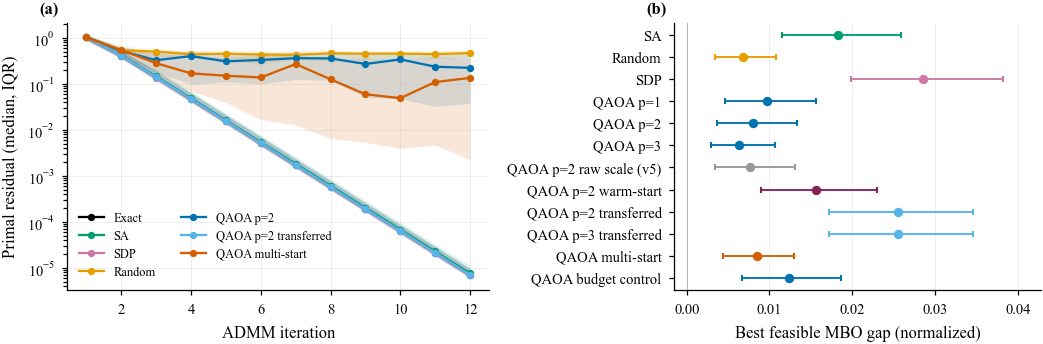

Saved figures/fig01_admm_outcome.png and figures/fig01_admm_outcome.pdf


In [34]:
# Figure 1: ADMM-level outcome (M5)
it = A["iters"]; F1_ARMS = ["Exact", "SA", "SDP", "Random", "QAOA p=2", "QAOA p=2 transferred", "QAOA multi-start"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.5), gridspec_kw={"width_ratios": [1.15, 1]})
for a in F1_ARMS:
    g = it[it.arm == a].groupby("iter")["resid"]; x = np.arange(1, K_MAIN + 1)
    a1.fill_between(x, g.quantile(0.25).clip(lower=1e-12), g.quantile(0.75), color=colr(a), alpha=0.15, lw=0)
    a1.plot(x, g.median().clip(lower=1e-12), "o-", color=colr(a), ms=2.5, label=a)
a1.set_yscale("log"); a1.set_xlabel("ADMM iteration"); a1.set_ylabel("Primal residual (median, IQR)")
a1.legend(ncol=2, loc="lower left", fontsize=6); panel_label(a1, "a")
ci_rows(a2, dA, [a for a in ORDER_A if a != "Exact"], "mbo_gap_best_unif", xlabel="Best feasible MBO gap (normalized)")
panel_label(a2, "b"); fig.tight_layout(); save_figure(fig, "fig01_admm_outcome")

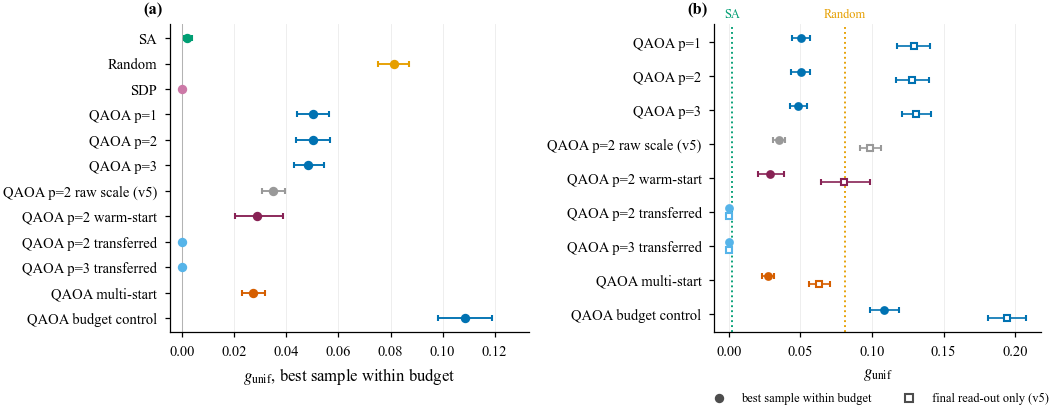

Saved figures/fig02_main_comparison.png and figures/fig02_main_comparison.pdf


In [35]:
# Figure 2: main comparison under both scoring rules (M1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 3.0), gridspec_kw={"width_ratios": [1.1, 1]})
ci_rows(a1, dA, [a for a in ORDER_A if a != "Exact"], "gap_unif", xlabel=r"$g_{\mathrm{unif}}$, best sample within budget")
panel_label(a1, "a")
y = np.arange(len(QAOA_A))[::-1]
for yi, a in zip(y, QAOA_A):
    s = dA[dA.arm == a]
    for metric, mk, off in (("gap_unif", "o", 0.12), ("gap_ro_unif", "s", -0.12)):
        m, lo, hi = bootstrap_ci(s[metric])
        a2.errorbar(m, yi + off, xerr=[[m - lo], [hi - m]], fmt=mk, color=colr(a), mfc="white" if mk == "s" else colr(a), ms=3.2, capsize=1.5, elinewidth=0.8)
for ref in ("Random", "SA"):
    m = dA[dA.arm == ref].gap_unif.mean(); a2.axvline(m, color=colr(ref), ls=":", lw=0.9)
    a2.text(m, len(QAOA_A) - 0.3, ref, color=colr(ref), fontsize=6, ha="center")
a2.set_yticks(y); a2.set_yticklabels(QAOA_A); a2.set_xlabel(r"$g_{\mathrm{unif}}$")
a2.plot([], [], "o", color="0.3", label="best sample within budget"); a2.plot([], [], "s", color="0.3", mfc="white", label="final read-out only (v5)")
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=6); a2.grid(axis="y", alpha=0); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig02_main_comparison")

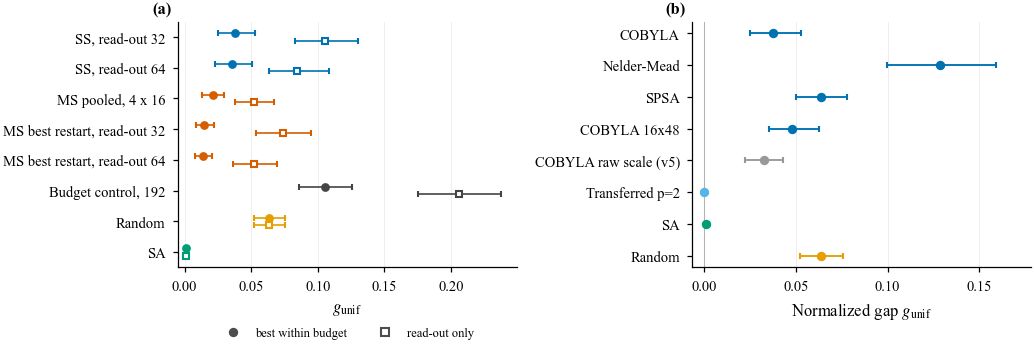

Saved figures/fig03_mechanism_ablation.png and figures/fig03_mechanism_ablation.pdf


In [36]:
# Figure 3: mechanism decomposition (M2) and optimizer ablation (M3)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.6))
arms3 = list(MECH); y = np.arange(len(arms3))[::-1]
for yi, a in zip(y, arms3):
    s = dM[dM.arm == a]
    for metric, mk, off in (("gap_unif", "o", 0.12), ("gap_ro_unif", "s", -0.12)):
        m, lo, hi = bootstrap_ci(s[metric])
        a1.errorbar(m, yi + off, xerr=[[m - lo], [hi - m]], fmt=mk, color=colr(a), mfc="white" if mk == "s" else colr(a), ms=3.2, capsize=1.5, elinewidth=0.8)
a1.set_yticks(y); a1.set_yticklabels(arms3); a1.set_xlabel(r"$g_{\mathrm{unif}}$"); a1.set_xlim(left=-0.005)
a1.plot([], [], "o", color="0.3", label="best within budget"); a1.plot([], [], "s", color="0.3", mfc="white", label="read-out only")
a1.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2); a1.grid(axis="y", alpha=0); panel_label(a1, "a")
ci_rows(a2, dB, list(ABL), "gap_unif"); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig03_mechanism_ablation")

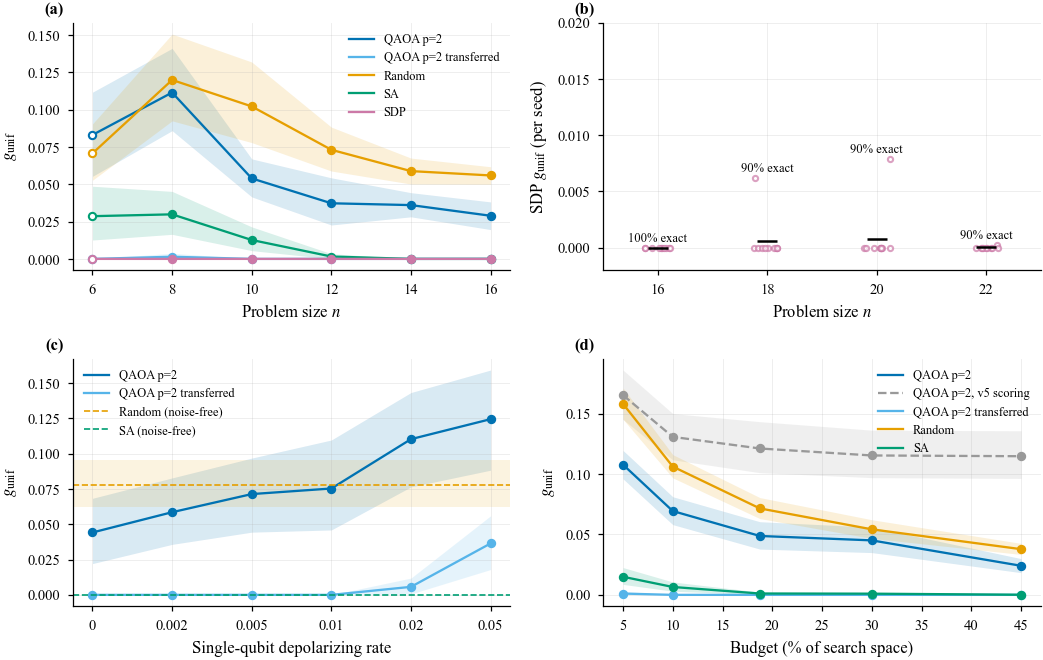

Saved figures/fig04_robustness.png and figures/fig04_robustness.pdf


In [37]:
# Figure 4: robustness (size, SDP extension, noise, budget)
fig, ax = plt.subplots(2, 2, figsize=(COL2, 4.6)); (a1, a2), (a3, a4) = ax
for a in ["QAOA p=2", "QAOA p=2 transferred", "Random", "SA", "SDP"]:
    s = dD[dD.arm == a]; ns = sorted(s.n.unique())
    line_ci(a1, ns, [s[s.n == n_].gap_unif for n_ in ns], a, colr(a), hollow_at=[6])
a1.set_xlabel("Problem size $n$"); a1.set_ylabel(r"$g_{\mathrm{unif}}$"); a1.set_xticks(SIZES); a1.legend(fontsize=6); panel_label(a1, "a")
rng_j = np.random.default_rng(0)
for n_, s in dX.groupby("n"):
    a2.plot(n_ + rng_j.uniform(-0.25, 0.25, len(s)), s.gap_unif, "o", color=C["SDP"], ms=2.5, alpha=0.7, mfc="white")
    a2.plot(n_, s.gap_unif.mean(), "_", color="k", ms=10, mew=1.2)
    a2.annotate(f"{s.hit.mean():.0%} exact", (n_, s.gap_unif.max()), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=6)
a2.set_ylim(-0.002, max(0.02, 1.25 * dX.gap_unif.max())); a2.set_xlim(min(SIZES_SDPX) - 1, max(SIZES_SDPX) + 1)
a2.set_xlabel("Problem size $n$"); a2.set_ylabel(r"SDP $g_{\mathrm{unif}}$ (per seed)"); a2.set_xticks(SIZES_SDPX); panel_label(a2, "b")
xs = np.arange(len(NOISE_LEVELS))
for a in ["QAOA p=2", "QAOA p=2 transferred"]:
    s = dE[dE.arm == a]; line_ci(a3, xs, [s[s.noise == p].gap_unif for p in NOISE_LEVELS], a, colr(a))
for ref in ("Random", "SA"):
    m, lo, hi = bootstrap_ci(dE[dE.arm == ref].gap_unif)
    a3.axhspan(lo, hi, color=colr(ref), alpha=0.12, lw=0); a3.axhline(m, color=colr(ref), ls="--", lw=0.8, label=f"{ref} (noise-free)")
a3.set_xticks(xs); a3.set_xticklabels([f"{p:g}" for p in NOISE_LEVELS]); a3.set_xlabel("Single-qubit depolarizing rate")
a3.set_ylabel(r"$g_{\mathrm{unif}}$"); a3.legend(fontsize=6); panel_label(a3, "c")
fr = np.array(BUDGET_FRACS) * 100
for a, metric, ls, lab in [("QAOA p=2", "gap_unif", "-", "QAOA p=2"), ("QAOA p=2, no top-up (v5)", "gap_ro_unif", "--", "QAOA p=2, v5 scoring"),
                           ("QAOA p=2 transferred", "gap_unif", "-", "QAOA p=2 transferred"), ("Random", "gap_unif", "-", "Random"), ("SA", "gap_unif", "-", "SA")]:
    s = dF[dF.arm == a]; line_ci(a4, fr, [s[s.frac == f][metric] for f in BUDGET_FRACS], lab, colr(a) if "v5" not in a else C["QAOA-raw"], ls=ls)
a4.set_xlabel("Budget (% of search space)"); a4.set_ylabel(r"$g_{\mathrm{unif}}$"); a4.legend(fontsize=6); panel_label(a4, "d")
fig.tight_layout(); save_figure(fig, "fig04_robustness")

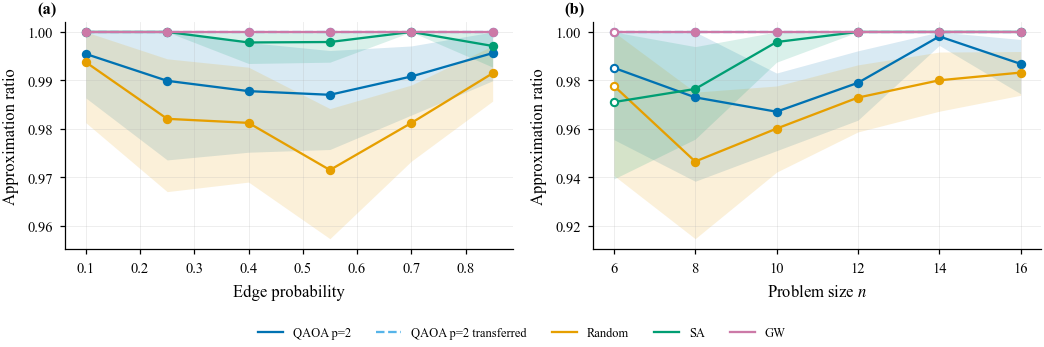

Saved figures/fig05_maxcut.png and figures/fig05_maxcut.pdf


In [38]:
# Figure 5: MaxCut
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL2, 2.4))
for a in ["QAOA p=2", "QAOA p=2 transferred", "Random", "SA", "GW"]:
    ls_ = "--" if "transferred" in a else "-"
    s = dGd[dGd.arm == a]; line_ci(a1, DENSITY_SWEEP, [s[s.p_edge == p].approx for p in DENSITY_SWEEP], a, colr(a), ls=ls_)
    s = dGs[dGs.arm == a]; ns = sorted(s.n.unique()); line_ci(a2, ns, [s[s.n == n_].approx for n_ in ns], a, colr(a), ls=ls_, hollow_at=[6])
a1.set_xlabel("Edge probability"); a1.set_ylabel("Approximation ratio"); panel_label(a1, "a")
fig.legend(*a1.get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=6, bbox_to_anchor=(0.5, -0.02))
a2.set_xlabel("Problem size $n$"); a2.set_ylabel("Approximation ratio"); a2.set_xticks(SIZES); panel_label(a2, "b")
fig.tight_layout(rect=[0, 0.07, 1, 1]); save_figure(fig, "fig05_maxcut")

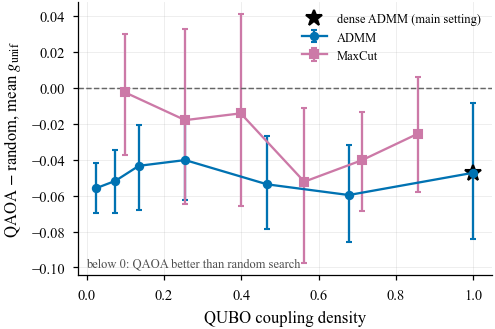

Saved figures/fig06_density.png and figures/fig06_density.pdf


In [39]:
# Figure 6: QAOA minus random search versus coupling density (M10)
fig, ax = plt.subplots(figsize=(COL1, 2.4))
for fam_, mk in (("ADMM", "o"), ("MaxCut", "s")):
    s = dens_tab[dens_tab.family == fam_].sort_values("density")
    ax.errorbar(s.density, s.delta, yerr=[s.delta - s.lo, s.hi - s.delta], fmt=mk + "-", ms=3.5, capsize=1.5,
                color=C["QAOA"] if fam_ == "ADMM" else C["GW"], label=f"{fam_}")
dd = dens_tab[(dens_tab.family == "ADMM") & (dens_tab.level == "dense")]
ax.plot(dd.density, dd.delta, "*", color="k", ms=8, label="dense ADMM (main setting)")
ax.axhline(0, color="0.4", lw=0.7, ls="--")
ax.text(0.02, 0.03, "below 0: QAOA better than random search", transform=ax.transAxes, fontsize=6, color="0.3")
ax.set_xlabel("QUBO coupling density"); ax.set_ylabel(r"QAOA $-$ random, mean $g_{\mathrm{unif}}$"); ax.legend(fontsize=6)
fig.tight_layout(); save_figure(fig, "fig06_density")

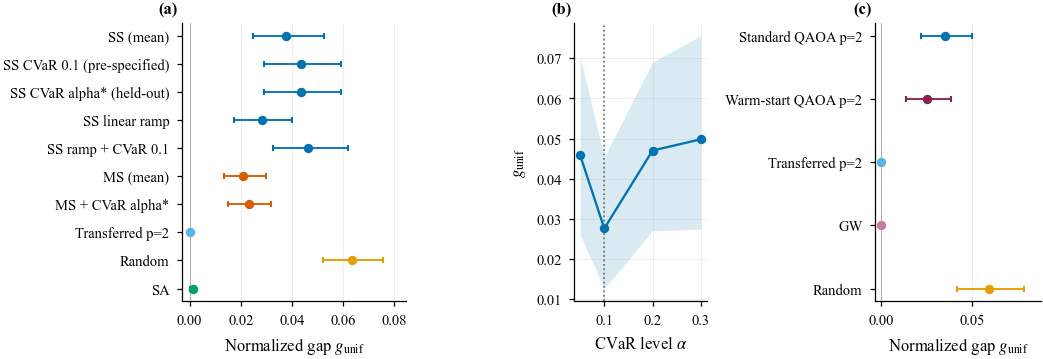

Saved figures/fig07_landscape.png and figures/fig07_landscape.pdf


In [40]:
# Figure 7: landscape mitigation
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(COL2, 2.6), gridspec_kw={"width_ratios": [1.35, 0.8, 1]})
ci_rows(a1, dL, list(LAND), "gap_unif"); panel_label(a1, "a")
sel = SEL["seeds"]; al = [float(a.split()[-1]) for a in sel_arms]
line_ci(a2, al, [sel[sel.arm == a].gap_unif for a in sel_arms], "CVaR, held-out seeds", C["QAOA"])
a2.axvline(ALPHA_STAR, color="0.4", ls=":", lw=0.8); a2.set_xlabel(r"CVaR level $\alpha$"); a2.set_ylabel(r"$g_{\mathrm{unif}}$"); panel_label(a2, "b")
ci_rows(a3, dW, list(WS), "gap_unif"); panel_label(a3, "c")
fig.tight_layout(); save_figure(fig, "fig07_landscape")

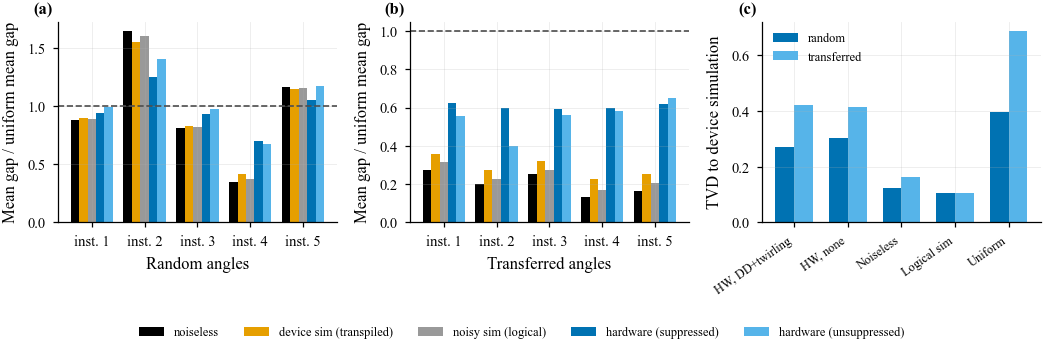

Saved figures/fig08_hardware.png and figures/fig08_hardware.pdf


In [41]:
# Figure 8: hardware validation (M4)
conds = [c_ for c_ in ["noiseless", "device sim (transpiled)", "noisy sim (logical)", "hardware (suppressed)", "hardware (unsuppressed)"]
         if c_ in set(dH.condition)]
ccol = {"noiseless": "#000000", "device sim (transpiled)": C["Sim"], "noisy sim (logical)": "#999999",
        "hardware (suppressed)": C["HW"], "hardware (unsuppressed)": "#56B4E9"}
fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.4))
for k, ang in enumerate(("random", "transferred")):
    axk = axs[k]; s = dH[dH.angles == ang]; seeds_ = sorted(s.seed.unique()); w = 0.8 / len(conds)
    for j, c_ in enumerate(conds):
        v = s[s.condition == c_].sort_values("seed").mean_gap_rel_uniform.values
        axk.bar(np.arange(len(seeds_)) + (j - (len(conds) - 1) / 2) * w, v, w, color=ccol[c_], label=c_)
    axk.axhline(1.0, color="0.3", ls="--", lw=0.8); axk.set_xticks(range(len(seeds_))); axk.set_xticklabels([f"inst. {i + 1}" for i in seeds_])
    axk.set_ylabel("Mean gap / uniform mean gap"); axk.set_xlabel(f"{ang.capitalize()} angles"); panel_label(axk, "ab"[k])
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=len(conds), fontsize=6, bbox_to_anchor=(0.5, -0.02))
if "tvd_vs_device" in dH:
    t_ = dH[dH.condition != "device sim (transpiled)"].groupby(["condition", "angles"]).tvd_vs_device.mean().unstack()
    short = {"hardware (suppressed)": "HW, DD+twirling", "hardware (unsuppressed)": "HW, none", "noiseless": "Noiseless",
             "noisy sim (logical)": "Logical sim", "uniform": "Uniform"}
    t_.index = [short.get(i, i) for i in t_.index]
    t_.plot.bar(ax=axs[2], color=[C["QAOA"], C["QAOA-T"]], width=0.7)
    for lab in axs[2].get_xticklabels(): lab.set_rotation(35); lab.set_ha("right")
    axs[2].set_ylabel("TVD to device simulation"); axs[2].set_xlabel(""); axs[2].legend(fontsize=6, title=None)
    axs[2].tick_params(axis="x", labelsize=6); panel_label(axs[2], "c")
fig.tight_layout(rect=[0, 0.08, 1, 1]); save_figure(fig, "fig08_hardware")

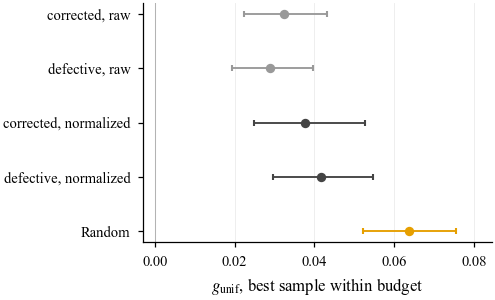

Saved figures/fig09_defect.png and figures/fig09_defect.pdf


In [42]:
# Figure 9: Hamiltonian-defect direction (M9)
fig, ax = plt.subplots(figsize=(COL1, 2.2))
labs = ["corrected, raw", "defective, raw", "corrected, normalized", "defective, normalized", "Random"]
ci_rows(ax, dJ, labs, "gap_unif", xlabel=r"$g_{\mathrm{unif}}$, best sample within budget")
fig.tight_layout(); save_figure(fig, "fig09_defect")

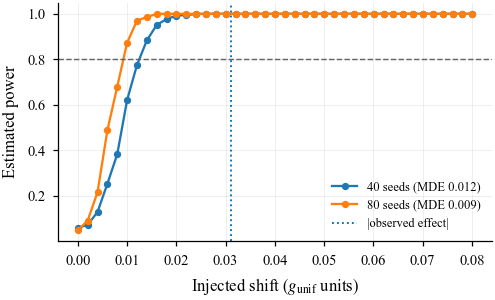

Saved figures/fig10_power.png and figures/fig10_power.pdf


In [43]:
# Figure 10: post hoc power (moderate issue)
fig, ax = plt.subplots(figsize=(COL1, 2.2))
for nt, pw in POWER.items():
    ax.plot(MDE_GRID, pw, "o-", ms=2.5, label=f"{nt} seeds (MDE {interp_mde(MDE_GRID, pw):.3f})")
ax.axhline(0.8, color="0.4", ls="--", lw=0.7); ax.axvline(abs(np.mean(mde_diffs)), color=C["QAOA"], ls=":", lw=0.9, label="|observed effect|")
ax.set_xlabel(r"Injected shift ($g_{\mathrm{unif}}$ units)"); ax.set_ylabel("Estimated power"); ax.legend(fontsize=6)
fig.tight_layout(); save_figure(fig, "fig10_power")

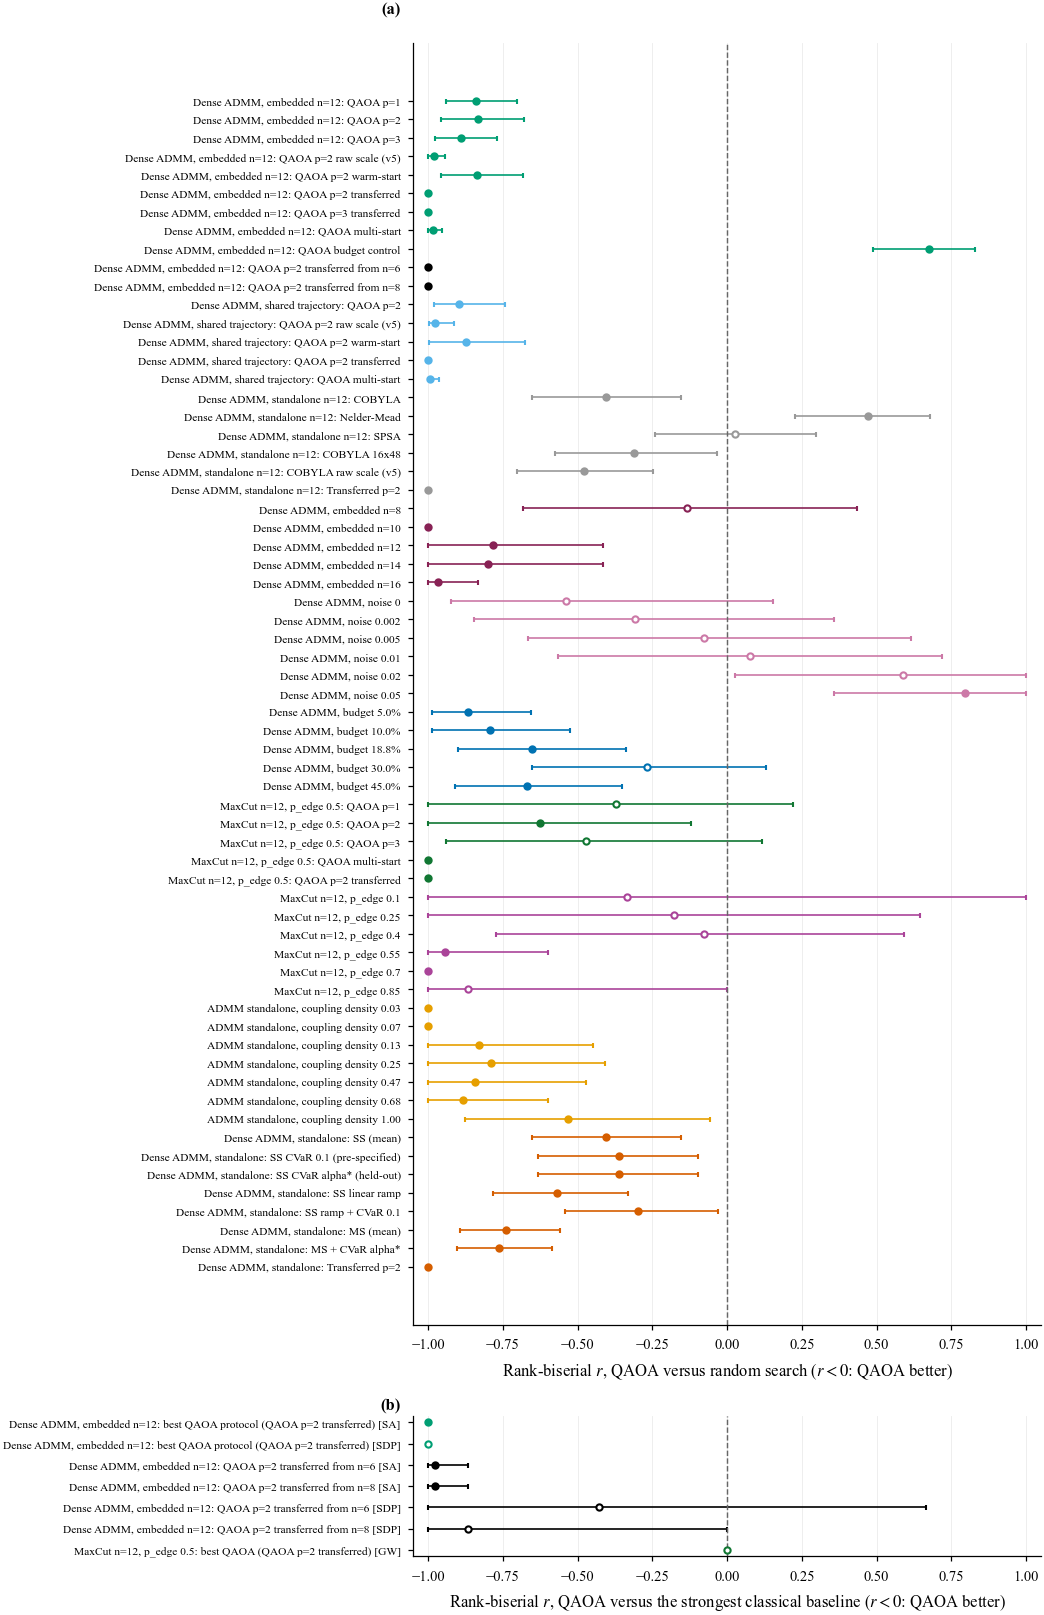

Saved figures/fig11_viability_map.png and figures/fig11_viability_map.pdf


In [44]:
# Figure 11: viability map (M7, M10)
comps = [c_ for c_ in ("Random", "SA", "SDP", "GW") if c_ in set(dV.comparator)]
vr = dV[dV.comparator == "Random"].reset_index(drop=True); vc = dV[dV.comparator != "Random"].reset_index(drop=True)
h_ = 0.14 * (len(vr) + len(vc)) + 1.0
fig, (a1, a2) = plt.subplots(2, 1, figsize=(COL2, h_), gridspec_kw={"height_ratios": [max(len(vr), 1), max(len(vc), 1)]})
_pal = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#882255", "#999999", "#000000", "#117733", "#AA4499"]
gcol = {g: _pal[i % len(_pal)] for i, g in enumerate(sorted(dV.group.unique()))}
for axk, s, ttl in ((a1, vr, "versus random search"), (a2, vc, "versus the strongest classical baseline")):
    y = np.arange(len(s))[::-1]
    for yi, (_, t) in zip(y, s.iterrows()):
        axk.errorbar(t.r, yi, xerr=[[t.r - t.r_lo], [t.r_hi - t.r]], fmt="o", ms=3, color=gcol[t.group],
                     mfc=gcol[t.group] if t.P < 0.05 else "white", capsize=1.2, elinewidth=0.8)
    axk.set_yticks(y); axk.set_yticklabels([f"{t.setting} [{t.comparator}]" if s is vc else t.setting for _, t in s.iterrows()], fontsize=5.5)
    axk.axvline(0, color="0.4", ls="--", lw=0.7); axk.set_xlim(-1.05, 1.05); axk.grid(axis="y", alpha=0)
    axk.set_xlabel(f"Rank-biserial $r$, QAOA {ttl} ($r<0$: QAOA better)")
panel_label(a1, "a"); panel_label(a2, "b")
fig.tight_layout(); save_figure(fig, "fig11_viability_map")

## 27. Review-to-manuscript map

| Item | Addressed in | What to report in the manuscript |
|---|---|---|
| M1 | S6, S10, S16, Fig. 2, Fig. 4d | Make best-sample-within-budget the primary QAOA score (same rule as SA and random); report the read-out score as a sensitivity result; state evaluations actually used; report whichever QAOA-versus-random result holds under the corrected score. |
| M2 | S12, Fig. 3a | Report the equal-read-out comparisons. Keep "restart diversity" only if the MS-versus-SS test at equal read-out is significant; otherwise attribute the v5 ordering to read-out size. |
| M3 | S6 (settings), S10a, S10, S13 | Report normalized Hamiltonian, COBYLA settings, transferred-angle and ADMM warm-start arms; state which protocol is strongest and use it for the headline comparison. |
| M3 scalability | S10b | Report that angles trained on n=6 and n=8 instances transfer to n=12; state the training cost and that it is excluded from the matched budget, like the SDP solve. |
| M4 | S22, Fig. 8 | Report means relative to the uniform reference, TVD and Hellinger fidelity, the optimized-angle condition, the logical-circuit simulation explaining the v5 sign, and suppressed versus unsuppressed runs. Remove "depolarizing" and "mitigated" wording. |
| M5 | S8, S10, S11, Fig. 1 | Cite Fig. 1 in the text; add the convergence table (final residual, best feasible MBO gap, MBO optimum found); report the shared-trajectory comparison; consider one abstract sentence on convergence. |
| M6 | S4, all sections, Fig. 4 to 6 | Use $g_{\text{unif}}$ as the primary normalized metric, approximation ratio for MaxCut, and probability of the optimum; redo trends and the density analysis in normalized units. |
| M7 | S24, Fig. 11 | Reduce to three or four contributions; retitle or answer the title with the viability map; state each result once in Results and move caveats to Limitations; use the eleven consolidated figures. |
| M8 | S5 | Describe the three-level gate (matrix, circuit, sampling) at n up to 16; remove the size-independence claim. |
| M9 | S20, Fig. 9 | State the direction plainly; report QAOA's own paired gap, defective versus corrected, under both protocols; report the scale ratio and rank correlation diagnostics. |
| M10 | S15, S16, S17, S18, S21, S24, Fig. 6, Fig. 11 | Report per-level QAOA-versus-random results (density, budget, noise, mitigation), the sign flip if it survives rescoring, and describe the MaxCut density curve per level. |
| Registry | S25 | Report the test count from `S25_test_registry.csv`, name every borderline test in the supplement, and report non-tied sample sizes for SDP-versus-SA. |
| MDE | S23, Fig. 10 | Report interpolated MDEs or drop the section; it is post hoc. |
| CVaR selection | S21 | Report alpha selected on held-out seeds and the matched MS+CVaR versus MS test. |
| Instance hardness | S10, S14b | Report SDP integrality gaps from the relaxation bound. |
| Specification gaps | S9 table | Include the specification table (or its content) in the Experimental Setup. |
| Code availability | repository | Provide an anonymized repository at submission. |
